# 부산항 추가 심화분석
## 추가 데이터 없이, 날씨·선박·대기 기록으로 개선안 찾기

**사용 파일은 `port+weather_raw.xlsx` 하나입니다. 기존 노트북을 먼저 실행할 필요도 없습니다.**

앞 노트북이 **“어디에서 시간이 길어졌을까?”**를 살펴봤다면, 이 파일은 **“왜 그런 모습이 나타났고, 어떤 운영 방법을 시험해 볼까?”**를 더 살펴봅니다.

### 급식실 줄을 떠올려 보세요
배가 항구에 들어오는 것은 급식실에 도착하는 것, 접안은 배식을 받기 시작하는 것과 비슷합니다. 줄이 길어지는 이유는 **한꺼번에 많이 와서**일 수도 있고, **앞사람의 배식이 오래 걸려서**일 수도 있습니다. 두 경우의 해결책은 다릅니다.

| 순서 | 쉬운 질문 | 결과를 쓰는 방법 |
|---|---|---|
| 1 | 큰 배라서 오래 걸릴까, 할 일이 많아서 오래 걸릴까? | 배 크기만으로 순서를 정하지 않기 |
| 2 | 바람·파도가 얼마나 나빠질 때 시간이 달라질까? | 주의 깊게 볼 기상 구간 찾기 |
| 3 | 바람과 파도가 함께 나쁘면 더 오래 걸릴까? | 한 가지 날씨만 보는 경보의 한계 확인 |
| 4 | **같은 배**도 날씨에 따라 시간이 달라질까? | 배 자체의 차이를 줄여 비교 |
| 5 | 앞에 남아 있던 배가 많으면 뒤의 배도 오래 걸릴까? | 줄서기와 접안 일정 개선 후보 찾기 |
| 6 | 특보가 끝난 뒤 며칠 동안 입항이 늘고 줄이 남을까? | 종료 후 집중 관리 기간 찾기 |
| 7 | 날씨와 표본 적체 정보를 더하면 다음 해 예측이 좋아질까? | 실제로 유용한 정보인지 시험 |
| 8 | 접안 순서를 바꾸면 누구의 대기가 줄고 늘까? | **가상 실험**으로 장단점 비교 |
| 9 | 그래서 무엇을 먼저 개선하면 좋을까? | 근거를 붙인 후보표 만들기 |

> **중요한 약속:** 이 자료로 없는 정보를 만들어 내지 않습니다. 실제 선석 수, 하역 시작·완료, 입출항 허용시각은 모릅니다. 따라서 ‘접안 이후 시간’은 순수 하역시간이 아니고, ‘표본 적체’는 항만 전체 혼잡도나 선석 점유율이 아닙니다. 안전기준을 정하거나 완화하는 분석도 아닙니다.

**방법:** 엑셀과 이 노트북을 같은 폴더에 두고 위에서부터 실행합니다. 결과 그림도 이 파일 안에 들어 있습니다. 원본 엑셀은 바꾸지 않습니다.

## 0. 준비와 설정

처음에는 설정을 바꾸지 않고 실행하세요. `TARGET_TERMINAL`은 자세히 볼 터미널입니다. 예를 들어 `"PNC"`를 `"BPT_S"`로 바꾸면 해당 그림이 바뀝니다.

필요한 프로그램 묶음은 pandas, numpy, matplotlib, openpyxl, scikit-learn입니다. 이미 설치되어 있으면 설치 명령을 실행할 필요가 없습니다. **외부 자료나 API는 받지 않습니다.**

패키지 설치가 필요한 환경에서만 별도 셀에 `%pip install pandas numpy matplotlib openpyxl scikit-learn`을 실행하세요.

In [3]:
from pathlib import Path
import warnings
import hashlib
import heapq
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown


# ===== 프로젝트 경로 설정 =====
def find_project_root(start=None):
    here = Path(start or Path.cwd()).resolve()

    for d in (here, *here.parents):
        if (
            (d / "pyproject.toml").is_file()
            and (d / "2.Data_Integrated Preprocessing").is_dir()
        ):
            return d

    raise FileNotFoundError(
        f"프로젝트 루트를 찾을 수 없습니다. 실행 위치: {here}"
    )


PROJECT_ROOT = find_project_root()

DATA_DIR = (
    PROJECT_ROOT
    / "2.Data_Integrated Preprocessing"
    / "Data"
)
FILE = DATA_DIR / "port+weather_raw.xlsx"
FILE_PATH = FILE  # 마지막 셀에서 쓰는 이름

# ===== 분석 설정 =====
START = pd.Timestamp("2020-01-01")
STOP = pd.Timestamp("2025-01-01")  # 이 시각은 포함하지 않음
TEST_START = pd.Timestamp("2024-01-01")
TARGET_TERMINAL = "PNC"

MIN_CELL = 20
MIN_REF = 12
BOOTSTRAPS = 300
SAVE_OUTPUTS = False
RUN_PREDICTION = True
RUN_TOY_SIMULATION = True

RESULT_DIR = (
    PROJECT_ROOT
    / "1.Rawdata_EDA"
    / "Output"
    / "부산항_추가분석_결과"
)

GT_EDGES = [
    0, 5000, 10000, 30000, 60000, 100000, np.inf
]
GT_LABELS = [
    "5천 이하",
    "5천~1만",
    "1만~3만",
    "3만~6만",
    "6만~10만",
    "10만 초과",
]
SEED = 20261026

# 운영기준이 아닌 연구 설정입니다.
# 6시간은 '비교용 긴 소요시간'입니다.
LONG_WAIT_H = 6
SIMULATED_SERVERS = [1, 2, 3]
SIMULATED_DURATION_SCALES = [0.75, 1.0, 1.25]
FAIR_WAIT_H = 12

if not FILE.is_file():
    raise FileNotFoundError(f"엑셀 파일이 없습니다: {FILE}")


# ===== 한글 글꼴 설정 =====
fonts = {f.name for f in font_manager.fontManager.ttflist}

for name in [
    "Malgun Gothic",
    "AppleGothic",
    "Apple SD Gothic Neo",
    "NanumGothic",
    "Noto Sans CJK KR",
    "Noto Sans CJK JP",
]:
    if name in fonts:
        plt.rcParams["font.family"] = name
        plt.rcParams["font.sans-serif"] = [name]
        print("사용 폰트:", name)
        break
else:
    print(
        "한글 폰트가 없어 글자가 깨질 수 있습니다. "
        "Windows에서는 맑은 고딕을 확인하세요."
    )

plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.size"] = 11
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


# ===== 표·그림 보관 함수 =====
TABLES = {}
FIGURES = []


def keep_table(name, table):
    TABLES[name] = table.copy()
    return table


def finish(fig, name):
    fig.tight_layout()
    FIGURES.append(name)

    if SAVE_OUTPUTS:
        RESULT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(
            RESULT_DIR / f"{name}.png",
            dpi=170,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)


def heatmap(
    table,
    title,
    name,
    unit="시간(h)",
    signed=False,
    counts=None,
):
    """빈칸은 0이 아니라 표본 부족입니다. 각 그림은 별도로 만듭니다."""
    if (
        table.empty
        or not np.isfinite(
            table.to_numpy(dtype=float)
        ).any()
    ):
        print(title, "→ 비교할 표본이 부족합니다.")
        return

    a = table.to_numpy(dtype=float)

    fig, ax = plt.subplots(
        figsize=(
            max(8.2, 1.15 * table.shape[1] + 3),
            max(3.8, 0.65 * table.shape[0] + 2),
        )
    )

    kwargs = {}
    if signed:
        lim = max(0.5, float(np.nanmax(np.abs(a))))
        kwargs.update(vmin=-lim, vmax=lim)

    im = ax.imshow(
        np.ma.masked_invalid(a),
        aspect="auto",
        **kwargs,
    )

    ax.set_xticks(range(len(table.columns)))
    ax.set_xticklabels(
        table.columns,
        rotation=25,
        ha="right",
    )
    ax.set_yticks(range(len(table.index)))
    ax.set_yticklabels(table.index)

    for i in range(a.shape[0]):
        for j in range(a.shape[1]):
            if not np.isfinite(a[i, j]):
                text = "―"
            elif signed:
                text = f"{a[i, j]:+.1f}"
            else:
                text = f"{a[i, j]:.1f}"

            if counts is not None and np.isfinite(a[i, j]):
                n = counts.reindex(
                    index=table.index,
                    columns=table.columns,
                ).iloc[i, j]

                if pd.notna(n):
                    text += f"\nn={int(n)}"

            ax.text(
                j,
                i,
                text,
                ha="center",
                va="center",
                fontsize=9,
                bbox=dict(
                    boxstyle="round,pad=0.15",
                    facecolor=fig.get_facecolor(),
                    edgecolor=fig.get_facecolor(),
                    alpha=0.85,
                ),
            )

    ax.set_title(title, pad=16, weight="bold")
    fig.colorbar(im, ax=ax, label=unit)
    finish(fig, name)


print("사용 파일:", FILE)
print(
    "분석 기간:",
    START.date(),
    "~",
    (STOP - pd.Timedelta(days=1)).date(),
)

사용 폰트: Malgun Gothic
사용 파일: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Data\port+weather_raw.xlsx
분석 기간: 2020-01-01 ~ 2024-12-31


## 1. 자료를 안전하게 연결하고, 시간을 다시 계산하기

**줄의 길이를 재기 전에 시계가 맞는지 확인하는 단계입니다.** 같은 이름의 배가 다른 날에도 오기 때문에 이름만으로 합치지 않습니다. 엑셀 행번호와 선박명·터미널·입항·접안·출항시각을 함께 확인합니다.

모든 시각은 파일 안내에 따라 한국시각(KST)으로 취급합니다. 기존 24시간 기상 집계는 그대로 사용하며 새 관측값을 만들지 않습니다.

시간은 세 가지로 나눕니다.

| 이름 | 계산 | 쉬운 뜻 |
|---|---|---|
| 접안 전 시간 | 접안 − 입항 | 항구에 들어온 뒤 접안까지 걸린 시간 |
| 접안 후 시간 | 항만 출항 − 접안 | 접안한 뒤 항구를 나갈 때까지 걸린 시간 |
| 재항시간 | 항만 출항 − 입항 | 항구에 머문 전체 시간 |

접안이 입항보다 **10분 이상 빠른 기록**, 접안 후 또는 전체 시간이 **10분 미만인 기록**은 계산 오류 가능성이 있어 분석에서 제외하고 개수를 보여줍니다. 0~10분 사이의 작은 역전은 별도로 표시하고, 적체 계산에 한해 접안시각을 입항시각과 같게 둡니다. 원시 시각은 남겨 둡니다.

**오래 머문 기록은 길다는 이유만으로 지우지 않습니다.** 30일 초과 기록을 따로 표시하며, 같은 배 비교에서는 포함·제외 결과를 둘 다 확인합니다. 배 크기가 없거나 작업량이 없는 기록도 전체 적체 계산에서 버리지 않고, 그 변수가 필요한 분석에서만 제외합니다.

In [4]:
with pd.ExcelFile(FILE, engine="openpyxl") as book:
    required_sheets = ["선박별_기상결합", "비교분석_핵심열", "항만별_일별", "추가_특보사건_162건"]
    missing = set(required_sheets) - set(book.sheet_names)
    if missing:
        raise ValueError(f"필요한 시트가 없습니다: {missing}")
    raw = pd.read_excel(book, "선박별_기상결합")
    core = pd.read_excel(book, "비교분석_핵심열")
    daily = pd.read_excel(book, "항만별_일별")
    events_raw = pd.read_excel(book, "추가_특보사건_162건")
    source_notes = {s: pd.read_excel(book, s) for s in ["품질점검", "분석안내", "병합_검증"] if s in book.sheet_names}

for frame in [raw, core, daily, events_raw]:
    frame.columns = frame.columns.astype(str).str.strip()

rownum = pd.to_numeric(core["원본행번호_엑셀"], errors="coerce")
if rownum.isna().any() or not rownum.is_unique or not rownum.between(2, len(raw)+1).all():
    raise ValueError("원본 행번호가 올바르지 않습니다. 이름만으로 임의 결합하지 않습니다.")
raw_indexed = raw.copy()
raw_indexed.index = np.arange(2, len(raw)+2)
aligned = raw_indexed.loc[rownum.astype(int)].reset_index(drop=True)
core = core.reset_index(drop=True)
for col in ["선박명", "터미널"]:
    if not core[col].astype(str).str.strip().equals(aligned[col].astype(str).str.strip()):
        raise ValueError(f"행 정합성 불일치: {col}")
for col in ["입항일시", "터미널_접안일시", "출항일시"]:
    a, b = pd.to_datetime(core[col], errors="coerce"), pd.to_datetime(aligned[col], errors="coerce")
    if not ((a == b) | (a.isna() & b.isna())).all():
        raise ValueError(f"행 정합성 불일치: {col}")

full = core.copy()
for col in aligned.columns.difference(core.columns):
    full[col] = aligned[col]
rename = {"원본행번호_엑셀":"row_id", "선박키":"ship_key", "선박명":"ship_name",
          "항만":"port", "터미널":"terminal", "총톤수":"gt",
          "터미널_총작업량":"work", "터미널_Shift수량":"shift",
          "입항일시":"arrival", "터미널_접안일시":"berth_raw", "출항일시":"departure"}
full = full.rename(columns=rename)
for col in ["arrival", "berth_raw", "departure"]:
    full[col] = pd.to_datetime(full[col], errors="coerce")
for col in ["gt", "work", "shift"]:
    if col in full:
        full[col] = pd.to_numeric(full[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
full["pre_raw_h"] = (full["berth_raw"]-full["arrival"]).dt.total_seconds()/3600
full["post_raw_h"] = (full["departure"]-full["berth_raw"]).dt.total_seconds()/3600
full["stay_h"] = (full["departure"]-full["arrival"]).dt.total_seconds()/3600
rules = {
    "시각 결측": full[["arrival","berth_raw","departure"]].isna().any(axis=1),
    "접안이 10분 이상 빠름": full["pre_raw_h"].le(-10/60),
    "접안 후 10분 미만": full["post_raw_h"].lt(10/60),
    "재항 10분 미만": full["stay_h"].lt(10/60),
    "터미널 결측": full["terminal"].isna(),
}
# 기준별 해당 수와 중복 제외 수를 구분합니다.
rule_names = ["시각 결측", "접안이 10분 이상 빠름", "접안 후 10분 미만", "재항 10분 미만", "터미널 결측"]
invalid = pd.concat(rules, axis=1).any(axis=1)
quality = pd.DataFrame({"점검": rule_names, "해당행수": [int(x.sum()) for x in rules.values()]})
quality.loc[len(quality)] = ["한 번 이상 해당: 중복 제외", int(invalid.sum())]
keep_table("01_제외기준", quality)

ships_all = full.loc[~invalid].copy()
ships_all["berth"] = ships_all[["arrival", "berth_raw"]].max(axis=1)
ships_all["pre_h"] = (ships_all["berth"]-ships_all["arrival"]).dt.total_seconds()/3600
ships_all["post_h"] = (ships_all["departure"]-ships_all["berth"]).dt.total_seconds()/3600
ships_all["small_reversal"] = ships_all["pre_raw_h"].lt(0)
ships_all["very_long"] = ships_all["stay_h"].gt(720)
ships_all["size"] = pd.cut(ships_all["gt"].where(ships_all["gt"].gt(0)), GT_EDGES, labels=GT_LABELS)
ships_all["work_band"] = pd.cut(ships_all["work"].where(ships_all["work"].gt(0)),
                                [0,500,1000,2000,4000,np.inf],
                                labels=["500 이하","500~1천","1천~2천","2천~4천","4천 초과"])
ships_all["terminal"] = ships_all["terminal"].astype(str).str.strip()
ships_all["ship_key"] = ships_all["ship_key"].astype("string").str.strip()
ships_all.loc[ships_all["ship_key"].isin(["", "nan", "None"]), "ship_key"] = pd.NA
ships = ships_all.loc[ships_all["arrival"].ge(START) & ships_all["arrival"].lt(STOP)].copy()
ships["year"] = ships["arrival"].dt.year
ships["month"] = ships["arrival"].dt.month
ships["season"] = (ships["month"] % 12 // 3).map({0:"겨울",1:"봄",2:"여름",3:"가을"})
ships["day"] = ships["arrival"].dt.normalize()
TERMINALS = sorted(ships["terminal"].unique())
if TARGET_TERMINAL not in TERMINALS:
    TARGET_TERMINAL = TERMINALS[0]
assert np.allclose(ships["pre_h"]+ships["post_h"], ships["stay_h"])

profile = ships.groupby("terminal").agg(
    기록수=("row_id","size"), 첫입항=("arrival","min"), 마지막입항=("arrival","max"),
    접안전중앙_h=("pre_h","median"), 접안후중앙_h=("post_h","median"),
    작은시각역전=("small_reversal","sum"), 삼십일초과=("very_long","sum"))
print(f"행 정합성 통과 | 원본 {len(raw):,}행 | 2020~2024년 유효 기항 {len(ships):,}행")
print("기항은 '한 번 방문한 기록'입니다. 같은 배의 반복 방문을 별도로 셉니다.")
display(quality)
display(keep_table("02_터미널현황", profile).round({c: 2 for c in profile.select_dtypes("number").columns}))

행 정합성 통과 | 원본 36,844행 | 2020~2024년 유효 기항 36,815행
기항은 '한 번 방문한 기록'입니다. 같은 배의 반복 방문을 별도로 셉니다.


,점검,해당행수
0,시각 결측,0
1,접안이 10분 이상 빠름,0
2,접안 후 10분 미만,0
3,재항 10분 미만,0
4,터미널 결측,0
5,한 번 이상 해당: 중복 제외,0


,기록수,첫입항,마지막입항,접안전중앙_h,접안후중앙_h,작은시각역전,삼십일초과
terminal,,,,,,,
BCT,2164,2022-04-18 13:30:00,2024-12-30 14:40:00,14.30,9.97,132,0
BNCT,4069,2020-01-01 12:46:00,2024-12-31 04:06:00,0.33,23.00,50,0
BPTC_G,5683,2020-01-01 12:12:00,2024-12-30 22:00:00,0.25,15.33,346,3
BPT_S,10346,2020-01-01 01:36:00,2024-12-31 03:48:00,0.25,17.67,455,3
HPNT,3034,2020-01-01 06:00:00,2024-12-30 08:46:00,0.22,19.77,159,0
PNC,7750,2020-01-01 09:40:00,2024-12-30 17:14:00,0.08,19.70,1838,1
PNIT,3769,2020-01-01 05:00:00,2024-12-29 03:05:00,0.33,23.48,63,0


### 이 파일만 사용할 때의 한계

바깥 자료를 더 받지 않는 대신, 다음 규칙을 지킵니다.

**첫째, 관측과 예측을 섞지 않습니다.** 주 분석은 기존 관측에서 만든 입항·접안 전 24시간 값을 사용합니다. 특보 때만 있는 해구 예측을 평상시 관측과 이어 붙여 비교하지 않습니다.

**둘째, 안개가 더 심한 터미널이라고 말하지 않습니다.** 파일의 안내에는 북항·신항 시정값에 공통 관측값이 사용됐다고 적혀 있습니다. 같은 시정에서 터미널별 시간이 어떻게 달랐는지만 봅니다.

**셋째, 없는 시간을 억지로 만들지 않습니다.** 순수 하역시간, 실제 운영 재개시각, 선석 점유율은 계산하지 않습니다. 항만 출항시각을 이용한 접안 후 시간을 보여줍니다. 기록상 예정시각 대체 이력도 완전히 분리할 수 없으므로 특정 터미널의 과실이나 설비 부족을 확정하지 않습니다.

**넷째, 표본이 없는 칸은 빈칸으로 둡니다.** 빈칸은 ‘영향이 없다’가 아니라 ‘비교할 재료가 부족하다’입니다. 공휴일 목록도 추가하지 않으므로 공휴일 효과까지 통제했다고 말하지 않습니다.

In [5]:
WEATHER = {
    "pre": {"풍속":"입항전_24h_평균풍속_mps", "파고":"입항전_24h_유의파고최대_m", "시정":"입항전_24h_시정최저_10m"},
    "post": {"풍속":"접안전_24h_평균풍속_mps", "파고":"접안전_24h_유의파고최대_m", "시정":"접안전_24h_시정최저_10m"},
}
EXPOSURE = {"pre":"입항전24h_특보노출시간_h", "post":"접안전24h_특보노출시간_h"}
PHASE_NAME = {"pre":"접안 전", "post":"접안 후"}
for col in set(c for d in WEATHER.values() for c in d.values()) | set(EXPOSURE.values()):
    if col not in ships:
        raise ValueError(f"필수 열 누락: {col}")
    ships[col] = pd.to_numeric(ships[col], errors="coerce").replace([np.inf,-np.inf], np.nan)
    ships.loc[ships[col].lt(0), col] = np.nan
for phase in WEATHER:
    for factor, col in WEATHER[phase].items():
        ships[f"{phase}_{factor}"] = ships[col]/100 if factor == "시정" else ships[col]
        # 시정 원단위 10m -> km: 값 / 100
    t = ships["arrival"] if phase == "pre" else ships["berth"]
    ships[f"{phase}_year"] = t.dt.year
    ships[f"{phase}_season"] = (t.dt.month % 12 // 3)
    ships[f"{phase}_month"] = t.dt.month

missing_weather = pd.DataFrame([
    {"항만":p,"분석구간":PHASE_NAME[phase],"요소":f,"전체기항":len(g),
     "결측기항":int(g[f"{phase}_{f}"].isna().sum()),"결측률_%":100*g[f"{phase}_{f}"].isna().mean()}
    for p,g in ships.groupby("port") for phase in WEATHER for f in WEATHER[phase]
])
display(keep_table("03_기상결측", missing_weather).round(1))
if "분석안내" in source_notes:
    display(source_notes["분석안내"].loc[source_notes["분석안내"].iloc[:,0].astype(str).str.contains("공통|터미널 출항|잔류선박|전24시간 품질")])

,항만,분석구간,요소,전체기항,결측기항,결측률_%
0,북항,접안 전,풍속,16029,387,2.4
1,북항,접안 전,파고,16029,372,2.3
2,북항,접안 전,시정,16029,51,0.3
3,북항,접안 후,풍속,16029,386,2.4
4,북항,접안 후,파고,16029,368,2.3
5,북항,접안 후,시정,16029,42,0.3
6,신항,접안 전,풍속,20786,370,1.8
7,신항,접안 전,파고,20786,3943,19.0
8,신항,접안 전,시정,20786,88,0.4
9,신항,접안 후,풍속,20786,366,1.8


,주제,설명
6,전24시간 품질,"최대순간풍속/시정 등 18개 이상, 파고 12개 이상 유효 관측 시 계산"
9,터미널 출항,56.6%가 실제 출항시각 결측. 계산용 종료 시각에 예정값 대체 포함
12,잔류선박,입항~출항 기간 내 입력된 매칭성공 풀컨테이너선만 계산. 부산항 전체 잔류선박 아님
14,공통 기상값,원본 강수량 및 시정은 북항/신항 같은 시각에서 동일함. 지점별 차이 해석 금지


## 2. 큰 배와 일이 많은 배를 구분하기

**큰 가방을 멘 학생이 항상 급식을 많이 먹는 것은 아닙니다.** 비슷하게 큰 배라도 부산항에서 싣고 내릴 양은 적을 수 있습니다.

아래 그림의 세로는 배 크기(GT), 가로는 이번 방문의 작업량입니다. 칸 안에는 접안 후 시간의 중앙값과 표본 수 `n`을 씁니다. **중앙값**은 시간을 짧은 순서대로 세웠을 때 가운데 값입니다.

작업량이 늘어날 때 시간이 길어지는지, 작업량이 비슷해도 크기별 차이가 있는지 보세요. GT는 배의 무게가 아니라 크기를 나타내는 지표이며, 작업량의 단위는 파일의 원래 수량 단위를 유지합니다. TEU나 톤으로 바꾸지 않습니다.

**연결할 개선안:** ‘큰 배 먼저/작은 배 먼저’보다 **그 방문의 예상 작업량**까지 보고 순서를 검토해야 하는지 판단합니다. 아직 날씨 영향을 따로 제거한 그림은 아닙니다.

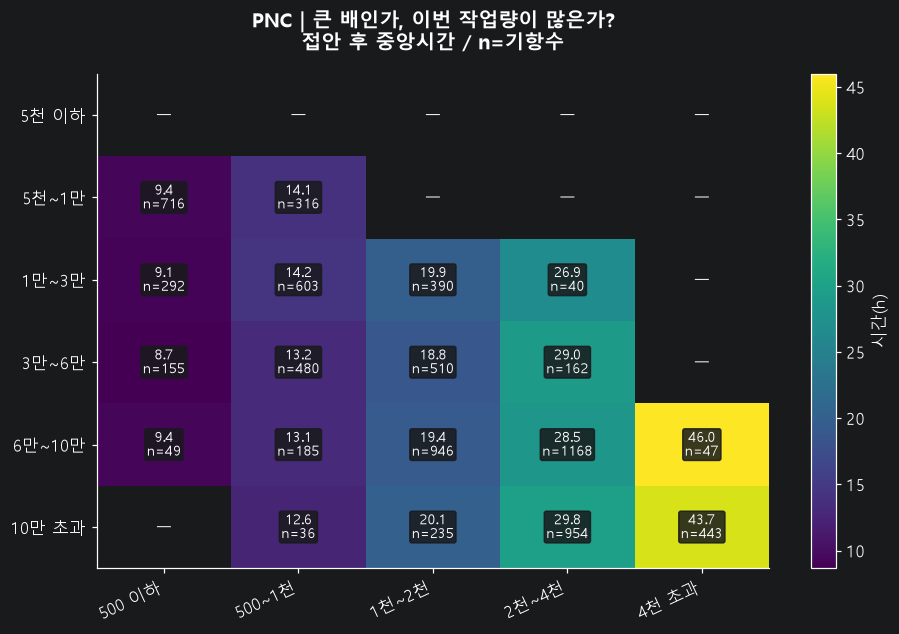

In [6]:
size_work = ships.groupby(["terminal","size","work_band"], observed=True).agg(
    n=("row_id","size"), median_post_h=("post_h","median"), median_pre_h=("pre_h","median")
).reset_index()
keep_table("04_크기와작업량", size_work)
g = size_work.loc[size_work["terminal"].eq(TARGET_TERMINAL)].copy()
g.loc[g["n"] < MIN_CELL, "median_post_h"] = np.nan
mat = g.pivot(index="size", columns="work_band", values="median_post_h").reindex(GT_LABELS)
nmat = g.pivot(index="size", columns="work_band", values="n")
heatmap(mat, f"{TARGET_TERMINAL} | 큰 배인가, 이번 작업량이 많은가?\n접안 후 중앙시간 / n=기항수", "04_size_work", counts=nmat)

## 3. 평상시와 비교할 자 만들기

다른 학생과 달리기 시간을 비교할 때 학년이 비슷해야 공정하겠지요? 여기서는 **같은 터미널·비슷한 크기·비슷한 작업량·비슷한 계절**의 기록을 찾습니다.

풍속·파고가 항만별 65백분위 이하, 시정이 25백분위 이상이고 직전 24시간 특보 노출이 없었던 기항을 ‘상대적으로 온화한 기록’으로 정합니다. 이 경계는 안전기준이 아니라 비교용 규칙입니다.

**추가시간 = 실제 시간 − 비교군의 중앙시간**입니다. 예를 들어 +3시간이면 비슷한 배들의 비교값보다 3시간 길었다는 뜻입니다. 날씨가 원인인 3시간이라고 확정하는 뜻은 아닙니다.

이번 단계는 과거를 설명하는 분석입니다. 해당 연도를 뺀 나머지 연도로 기준을 만들며, 미래 연도가 참조될 수 있습니다. 따라서 **이 값을 다음 해 예측에 재사용하지 않습니다.** 뒤의 예측 실험은 2024년 이전 자료로 따로 학습합니다.

표본이 부족하면 같은 터미널·크기·작업량까지만 맞춥니다. 그래도 부족하면 계산하지 않습니다. 다른 터미널의 값을 대신 넣지 않습니다.

In [7]:
threshold_rows = []
for phase in WEATHER:
    ships[f"{phase}_calm"] = False
    for factor in WEATHER[phase]:
        ships[f"{phase}_bad_{factor}"] = pd.Series(pd.NA, index=ships.index, dtype="boolean")
    for port, g in ships.groupby("port"):
        good = pd.Series(True, index=g.index)
        for factor in WEATHER[phase]:
            col = f"{phase}_{factor}"
            q = g[col].quantile([.2,.25,.5,.65,.8])
            if factor == "시정":
                calm = g[col].ge(q.loc[.25]) & g[col].notna()
                bad = g[col].le(q.loc[.2]) & g[col].lt(q.loc[.5])
            else:
                calm = g[col].le(q.loc[.65]) & g[col].notna()
                bad = g[col].ge(q.loc[.8]) & g[col].gt(q.loc[.5])
            good &= calm
            ships.loc[g.index[g[col].notna()], f"{phase}_bad_{factor}"] = bad.loc[g[col].notna()]
            threshold_rows.append({"항만":port,"구간":PHASE_NAME[phase],"요소":factor,
                                   "P20":q.loc[.2],"P50":q.loc[.5],"P65":q.loc[.65],"P80":q.loc[.8]})
        good &= g[EXPOSURE[phase]].eq(0)  # 결측은 '특보 없음'으로 바꾸지 않음
        ships.loc[g.index, f"{phase}_calm"] = good
    ships[f"{phase}_baseline"] = np.nan
    ships[f"{phase}_reference_n"] = 0
    ships[f"{phase}_reference_level"] = "표본 부족"
    levels = [(["terminal","size","work_band",f"{phase}_season"], "크기·작업량·계절"),
              (["terminal","size","work_band"], "크기·작업량")]
    for year in sorted(ships[f"{phase}_year"].dropna().unique()):
        test_idx = ships.index[ships[f"{phase}_year"].eq(year)]
        train = ships.loc[ships[f"{phase}_year"].ne(year) & ships[f"{phase}_calm"]]
        for keys, label in levels:
            left_idx = test_idx[ships.loc[test_idx, f"{phase}_baseline"].isna()]
            if len(left_idx) == 0: break
            ref = train.groupby(keys, observed=True)[f"{phase}_h"].agg(median="median", n="size").reset_index()
            ref = ref.loc[ref["n"].ge(MIN_REF)]
            left = ships.loc[left_idx, keys].copy()
            left["_index"] = left.index
            out = left.merge(ref, on=keys, how="left", validate="many_to_one").set_index("_index")
            usable = out.index[out["median"].notna()]
            ships.loc[usable, f"{phase}_baseline"] = out.loc[usable,"median"]
            ships.loc[usable, f"{phase}_reference_n"] = out.loc[usable,"n"].astype(int)
            ships.loc[usable, f"{phase}_reference_level"] = label
    ships[f"{phase}_excess"] = ships[f"{phase}_h"] - ships[f"{phase}_baseline"]

baseline_coverage = pd.DataFrame([
    {"터미널":t,"구간":PHASE_NAME[p],"전체기항":len(g),
     "비교가능기항":int(g[f"{p}_baseline"].notna().sum()),
     "계절까지일치":int(g[f"{p}_reference_level"].eq("크기·작업량·계절").sum())}
    for t,g in ships.groupby("terminal") for p in WEATHER])
display(keep_table("05_기준경계값", pd.DataFrame(threshold_rows)).round(2))
display(keep_table("06_비교가능표본", baseline_coverage))

,항만,구간,요소,P20,P50,P65,P80
0,북항,접안 전,풍속,1.37,1.88,2.21,2.68
1,북항,접안 전,파고,0.50,0.80,1.00,1.30
2,북항,접안 전,시정,5.36,16.45,23.57,35.59
3,신항,접안 전,풍속,1.60,2.07,2.36,2.79
4,신항,접안 전,파고,0.40,0.50,0.70,0.90
5,신항,접안 전,시정,5.13,16.37,23.62,35.12
6,북항,접안 후,풍속,1.37,1.88,2.20,2.67
7,북항,접안 후,파고,0.50,0.80,1.00,1.30
8,북항,접안 후,시정,5.36,16.47,23.64,35.70
9,신항,접안 후,풍속,1.61,2.07,2.36,2.80


,터미널,구간,전체기항,비교가능기항,계절까지일치
0,BCT,접안 전,2164,1801,1122
1,BCT,접안 후,2164,1801,1154
2,BNCT,접안 전,4069,3883,2923
3,BNCT,접안 후,4069,3851,2895
4,BPTC_G,접안 전,5683,5521,5276
5,BPTC_G,접안 후,5683,5521,5270
6,BPT_S,접안 전,10346,10232,9915
7,BPT_S,접안 후,10346,10232,9924
8,HPNT,접안 전,3034,2845,1670
9,HPNT,접안 후,3034,2845,1774


## 4. 바람과 파도가 어느 정도일 때 달라질까?

지금까지 ‘나쁜 날/좋은 날’ 두 집단을 봤다면, 이번에는 기상 값을 여러 칸으로 나눕니다. **시험 점수를 60점 이하, 60~80점, 80점 이상으로 나누어 보는 것**과 비슷합니다.

풍속은 입항 또는 접안 전 24시간의 평균, 파고는 그 24시간의 최대 유의파고, 시정은 그 24시간의 가장 짧은 거리입니다. 시정은 작을수록 멀리 보기 어렵습니다.

그림 숫자는 **비슷한 조건의 평상시 기준보다 몇 시간 길거나 짧았는지**입니다. 양수이면 길고, 음수이면 짧습니다. 표본이 20기항 미만이거나 서로 다른 4주 미만에만 관측되면 빈칸입니다. ±0.0으로 보이는 작은 차이는 반올림된 값입니다. 자세한 수치는 결과표에서 확인할 수 있습니다.

**연결할 개선안:** 시간이 꾸준히 길어지는 구간이 여러 해에 반복되면, 그 조건에서 일정 재확인과 접안예정시각 갱신을 먼저 검토합니다. 여기서 찾은 수치는 운항 중단·재개 기준이 아닙니다. 나머지 날씨의 영향까지 완전히 분리한 그림도 아닙니다.

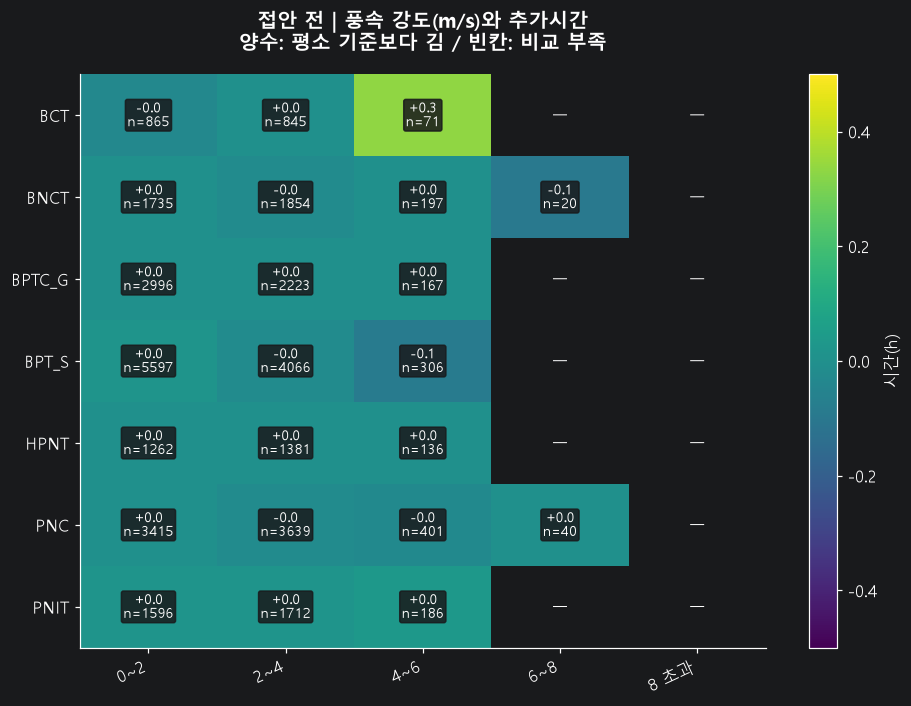

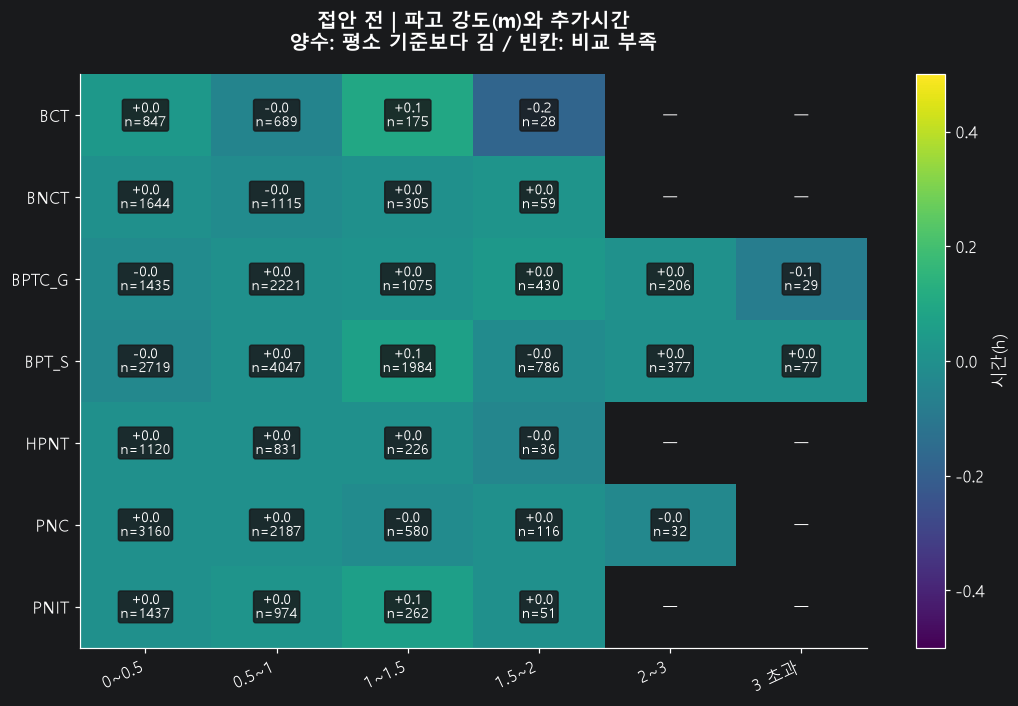

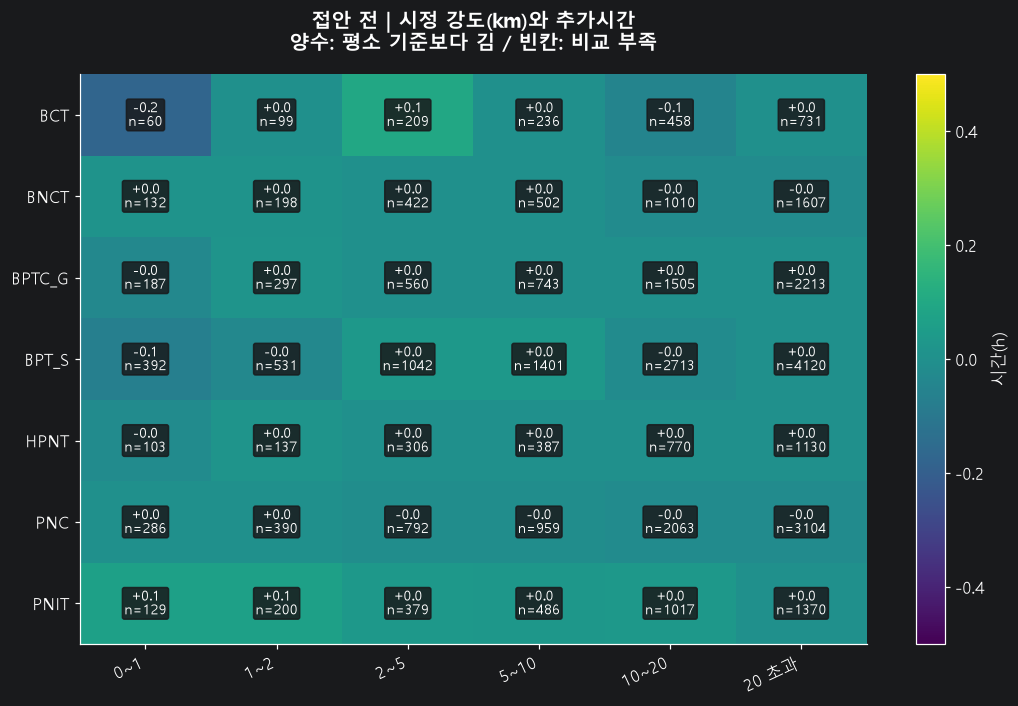

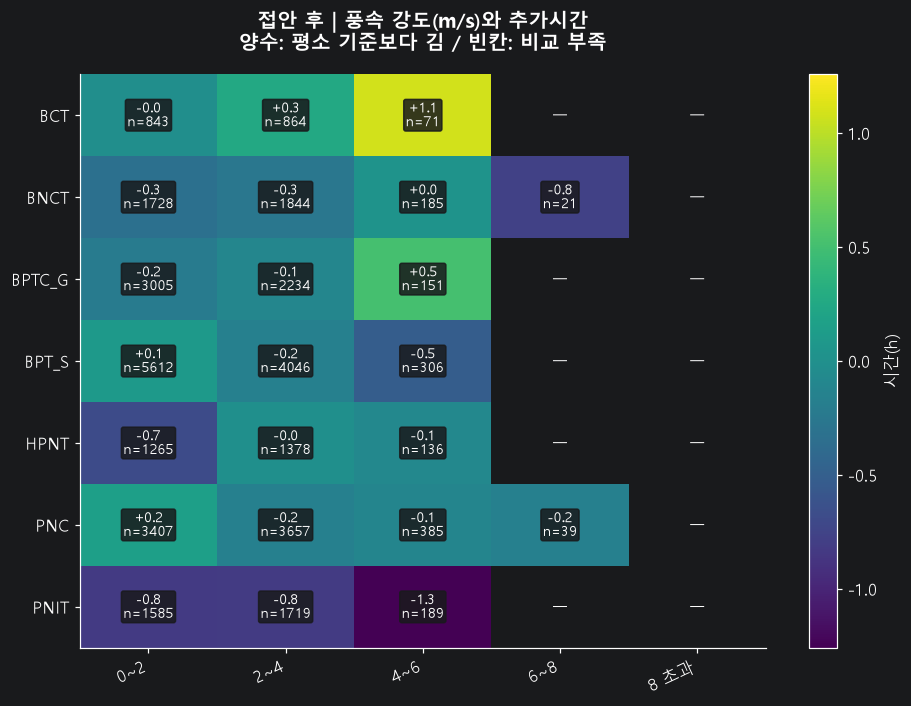

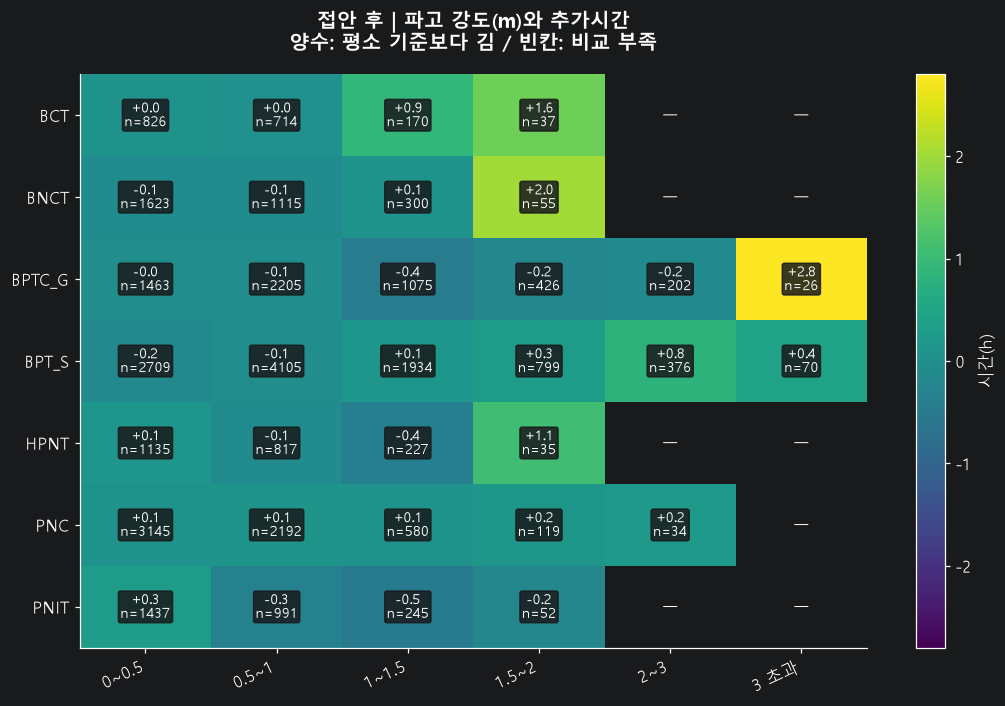

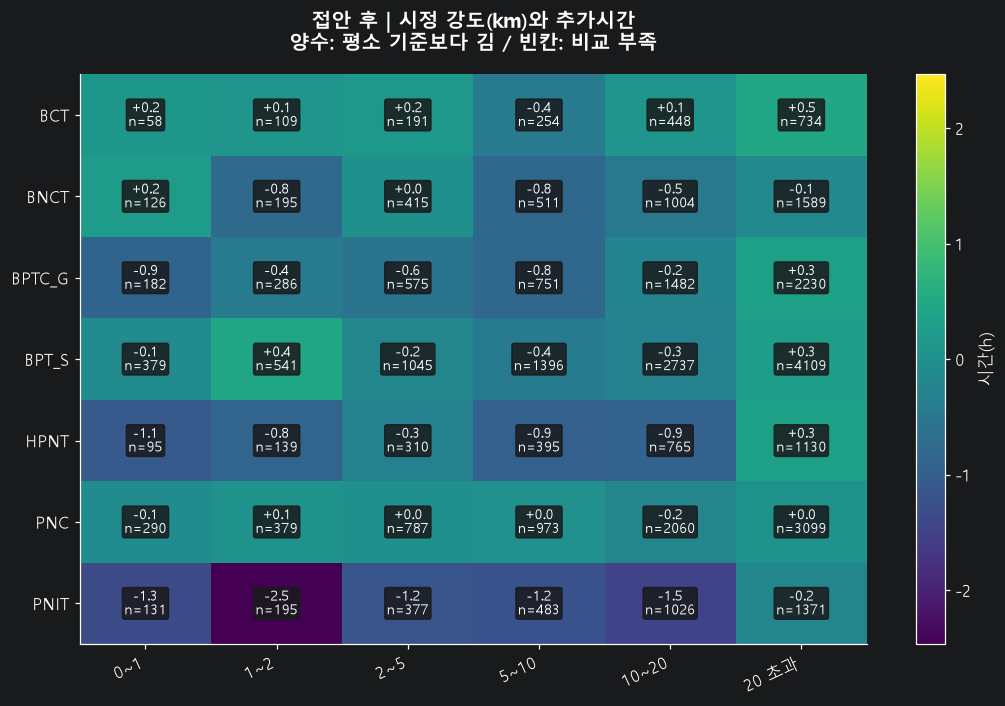

In [8]:
BANDS = {
    "풍속": ([0,2,4,6,8,np.inf], ["0~2","2~4","4~6","6~8","8 초과"], "m/s"),
    "파고": ([0,.5,1,1.5,2,3,np.inf], ["0~0.5","0.5~1","1~1.5","1.5~2","2~3","3 초과"], "m"),
    "시정": ([0,1,2,5,10,20,np.inf], ["0~1","1~2","2~5","5~10","10~20","20 초과"], "km"),
}
dose_rows = []
for phase in WEATHER:
    stamp = ships["arrival"] if phase == "pre" else ships["berth"]
    for factor, (edges, labels, unit) in BANDS.items():
        tmp = ships.copy()
        tmp["weather_bin"] = pd.cut(tmp[f"{phase}_{factor}"], edges, labels=labels, include_lowest=True)
        tmp["week"] = stamp.dt.to_period("W").astype(str)
        tmp = tmp.loc[tmp[f"{phase}_excess"].notna() & tmp["weather_bin"].notna()]
        for grouping in [["terminal"], ["terminal","size"]]:
            for keys, g in tmp.groupby(grouping+["weather_bin"], observed=True):
                keys = keys if isinstance(keys, tuple) else (keys,)
                row = dict(zip(grouping+["weather_bin"], keys))
                row.update(phase=phase, factor=factor, n=len(g), weeks=g["week"].nunique(),
                           median_excess=g[f"{phase}_excess"].median(),
                           mean_excess=g[f"{phase}_excess"].mean(), years=g[f"{phase}_year"].nunique())
                row["scope"] = "터미널" if len(grouping)==1 else "터미널×크기"
                dose_rows.append(row)
dose = pd.DataFrame(dose_rows)
dose["show_value"] = dose["median_excess"].where(dose["n"].ge(MIN_CELL) & dose["weeks"].ge(4))
keep_table("07_기상강도별_추가시간", dose)
for phase in WEATHER:
    for factor, (_, labels, unit) in BANDS.items():
        d = dose.loc[dose["scope"].eq("터미널") & dose["phase"].eq(phase) & dose["factor"].eq(factor)]
        mat = d.pivot(index="terminal", columns="weather_bin", values="show_value").reindex(index=TERMINALS,columns=labels)
        nn = d.pivot(index="terminal", columns="weather_bin", values="n")
        heatmap(mat, f"{PHASE_NAME[phase]} | {factor} 강도({unit})와 추가시간\n양수: 평소 기준보다 김 / 빈칸: 비교 부족", f"07_dose_{phase}_{factor}", signed=True, counts=nn)

### 같은 터미널 안에서 배 크기별로 다시 보기

터미널이 다르면 작업 방식도 다를 수 있습니다. 아래 그림은 `TARGET_TERMINAL` **하나 안에서** 비교합니다. 작은 배가 다른 항만에 더 많이 온다는 차이를 조금 줄일 수 있습니다.

**읽는 순서:** 같은 세로줄에서 배 크기별 숫자를 비교하고, 같은 가로줄에서 기상이 달라질 때 숫자가 변하는지 보세요. 빈칸이 많으면 그 크기의 배에 대한 결론은 보류합니다.

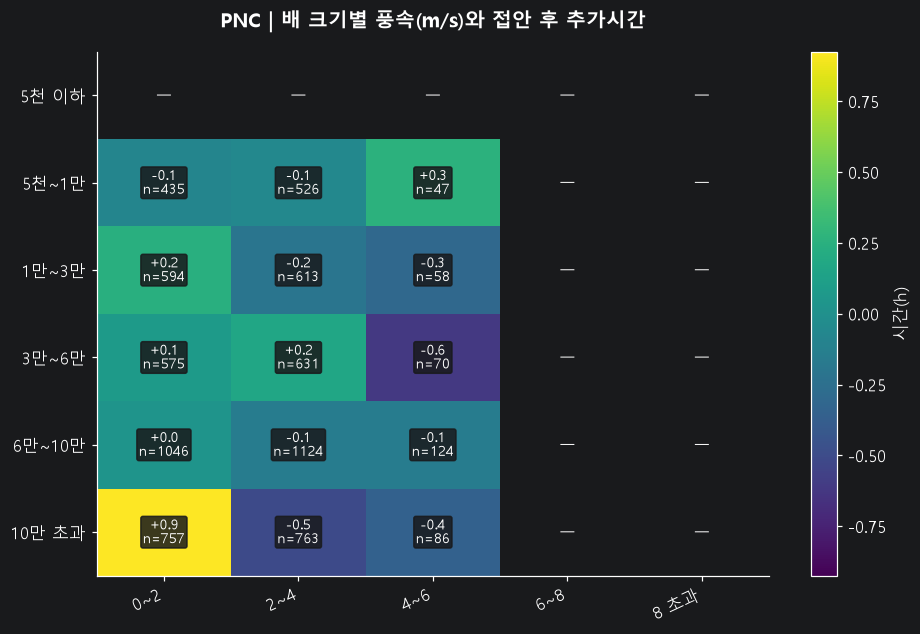

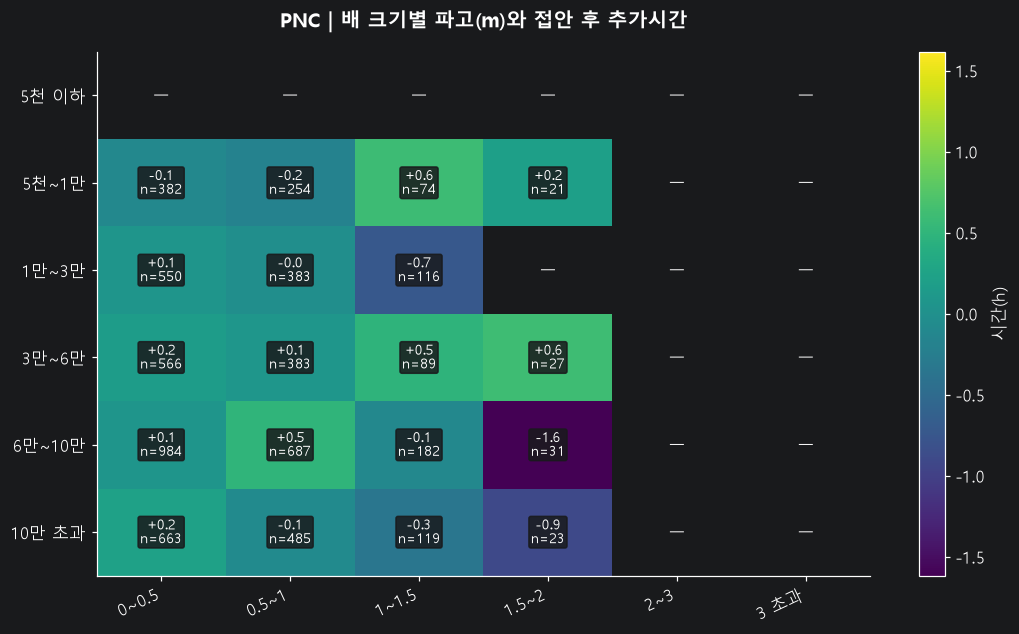

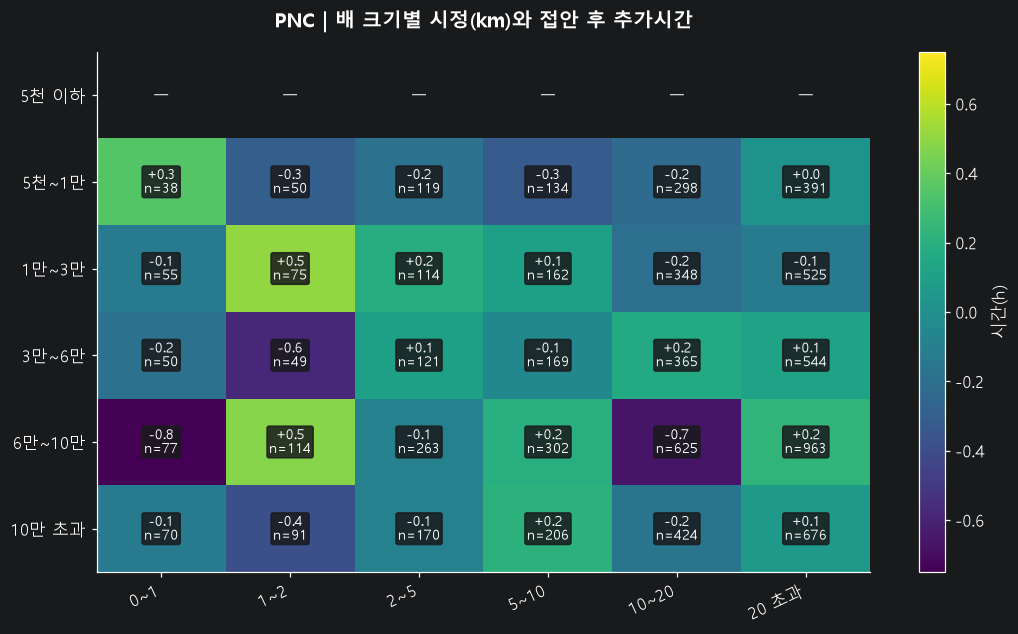

In [9]:
for factor, (_, labels, unit) in BANDS.items():
    d = dose.loc[dose["scope"].eq("터미널×크기") & dose["terminal"].eq(TARGET_TERMINAL)
                 & dose["phase"].eq("post") & dose["factor"].eq(factor)]
    if d.empty: continue
    mat = d.pivot(index="size", columns="weather_bin", values="show_value").reindex(index=GT_LABELS,columns=labels)
    nn = d.pivot(index="size", columns="weather_bin", values="n")
    heatmap(mat, f"{TARGET_TERMINAL} | 배 크기별 {factor}({unit})와 접안 후 추가시간", f"08_size_{factor}", signed=True, counts=nn)

## 5. 바람과 파도가 함께 나쁘면?

비만 오는 날과 비바람이 함께 부는 날은 다를 수 있습니다. 여기서는 풍속과 파고를 네 경우로 나눕니다.

**둘 다 상대적으로 낮음 / 바람만 높음 / 파고만 높음 / 둘 다 높음.** ‘높음’은 해당 항만 전체 기간의 상위 20% 수준입니다. 같은 값이 많이 반복되면 경계가 겹치지 않게 처리합니다. 나머지 집단도 완전히 맑은 날이라는 뜻은 아닙니다.

이 표는 **조건을 묶어 보는 그림**이지, 바람과 파도의 각각의 인과효과를 더한 계산이 아닙니다. 바람과 파고가 늘 함께 나빠져 ‘한쪽만 높은 날’이 적으면 각 요소의 역할을 구분하기 어렵다는 사실 자체가 중요한 결과입니다.

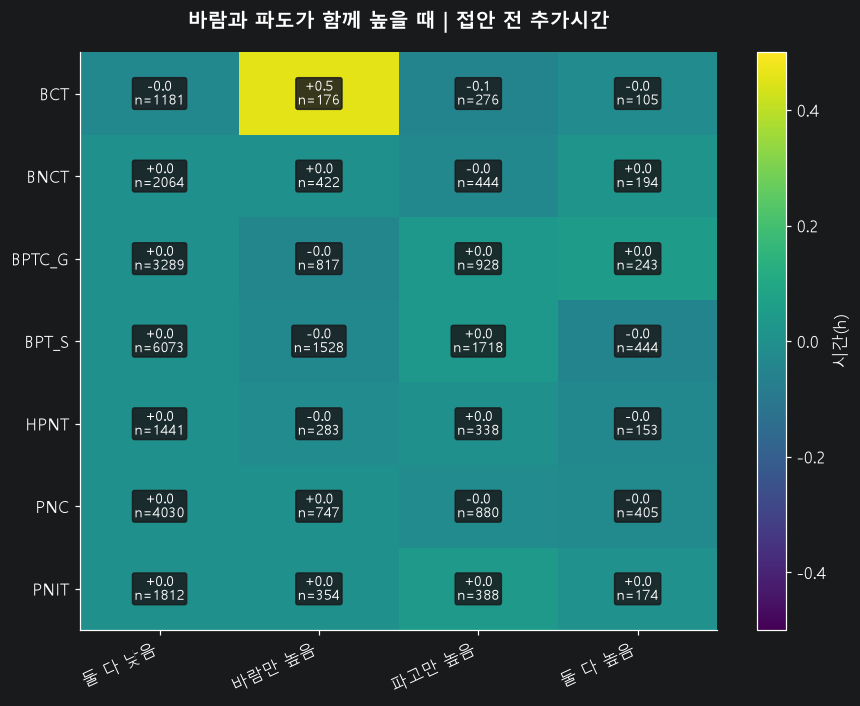

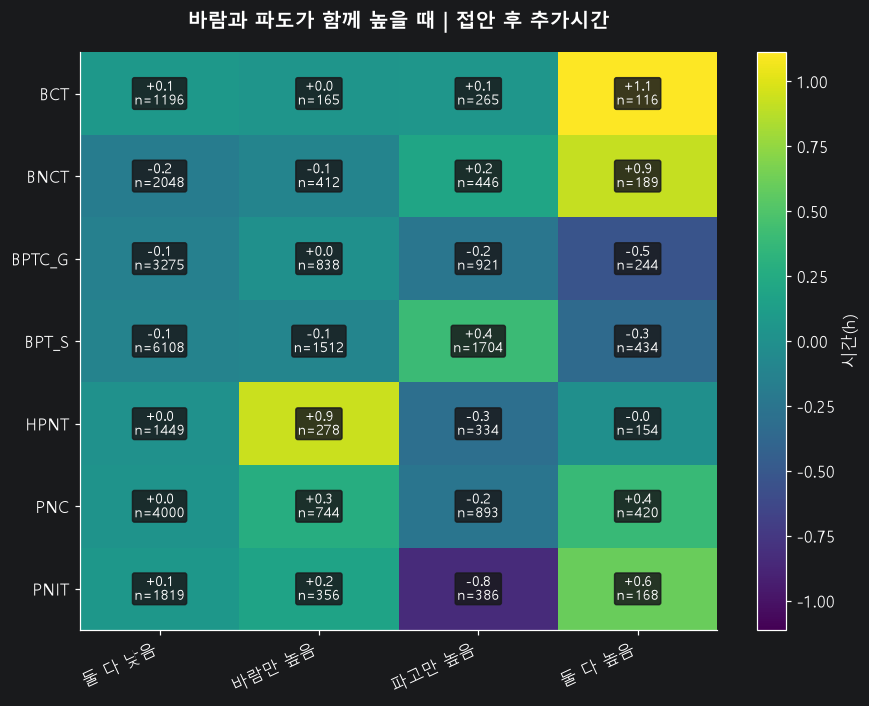

In [10]:
COMBO_ORDER = ["둘 다 낮음", "바람만 높음", "파고만 높음", "둘 다 높음"]
combo_rows = []
for phase in WEATHER:
    a = ships[f"{phase}_bad_풍속"]
    b = ships[f"{phase}_bad_파고"]
    valid = a.notna() & b.notna()
    ships[f"{phase}_combo"] = pd.Series(pd.NA, index=ships.index, dtype="string")
    aa, bb = a.loc[valid].astype(bool), b.loc[valid].astype(bool)
    ships.loc[valid, f"{phase}_combo"] = np.select(
        [~aa & ~bb, aa & ~bb, ~aa & bb, aa & bb], COMBO_ORDER, default="미분류")
    for (term, combo), g in ships.loc[ships[f"{phase}_excess"].notna()].groupby(["terminal",f"{phase}_combo"]):
        combo_rows.append({"terminal":term,"phase":phase,"combo":combo,"n":len(g),
                           "median_excess":g[f"{phase}_excess"].median()})
combo = pd.DataFrame(combo_rows)
combo["value"] = combo["median_excess"].where(combo["n"].ge(MIN_CELL))
keep_table("09_복합기상", combo)
for phase in WEATHER:
    g = combo.loc[combo["phase"].eq(phase)]
    heatmap(g.pivot(index="terminal", columns="combo", values="value").reindex(columns=COMBO_ORDER),
            f"바람과 파도가 함께 높을 때 | {PHASE_NAME[phase]} 추가시간", f"09_combo_{phase}", signed=True,
            counts=g.pivot(index="terminal", columns="combo", values="n"))

## 6. 같은 배의 다른 방문과 비교하기

**달리기를 잘하는 학생과 못하는 학생을 비교하는 대신, 같은 학생의 맑은 날 기록과 비 오는 날 기록을 비교합니다.** 이 파일의 선박키로 같은 배를 찾고, 같은 터미널 방문끼리만 비교합니다.

비교 규칙은 다음과 같습니다. 같은 계절, 방문 간격 180일 이내, 작업량의 큰 값이 작은 값의 1.25배 이내, 총톤수 차이 5% 이내를 만족해야 합니다. ‘날씨가 나쁜 방문’ 하나에 ‘온화한 방문’ 하나를 연결합니다. 같은 분석 안에서는 온화한 방문을 반복해서 돌려 쓰지 않습니다.

기상요소 하나만 나쁜 방문으로 제한하지 않으므로 **다른 악천후가 함께 있었다면 그 영향도 섞일 수 있습니다.** 선박키가 비어 있는 배는 이름으로 억지 연결하지 않습니다.

**불확실성 막대:** 나쁜 날들이 몰린 달을 묶어서 여러 번 다시 뽑아 결과를 계산합니다. 여러 기항이 같은 악천후의 영향을 함께 받았다는 점을 조금 반영합니다. 이 범위가 0을 걸치면 ‘분명히 길어졌다’고 말하기 조심스럽습니다. 표본 20쌍·6개월 묶음 이상일 때만 범위를 표시하며, 엄밀한 인과 검정은 아닙니다.

**연결할 개선안:** 같은 배에서도 접안 전 시간이 반복해서 길면 접안 일정 안내, 접안 후 시간이 길면 작업 종료예정시각의 갱신을 우선 후보로 검토합니다.

좋은/나쁜 기상조건은 입항 또는 접안 **직전 24시간**을 기준으로 합니다. 그 뒤 체류 중에 발생한 다른 기상 변화까지 분리한 것은 아닙니다.

,terminal,phase,factor,pairs,ships,months,mean_delta,median_delta,ci_low,ci_high,years_evaluable,years_positive,mean_without_30days,pairs_without_30days
0,BCT,post,시정,121,36,27,-0.12,0.27,-1.05,0.62,3,1,-0.12,121
1,BCT,post,파고,138,37,30,0.55,0.20,-0.23,1.26,3,3,0.55,138
2,BCT,post,풍속,122,34,29,0.22,0.15,-0.55,1.00,3,1,0.22,122
3,BCT,pre,시정,136,42,27,-1.83,0.16,-4.90,0.35,3,1,-1.83,136
4,BCT,pre,파고,132,35,28,-1.74,0.11,-6.19,2.36,3,2,-1.74,132
5,BCT,pre,풍속,118,36,28,1.32,0.05,-3.67,6.33,3,2,1.32,118
6,BNCT,post,시정,97,57,36,-0.06,1.10,-1.60,1.19,4,3,-0.06,97
7,BNCT,post,파고,117,60,39,-0.47,0.07,-2.10,0.82,4,2,-0.47,117
8,BNCT,post,풍속,108,56,43,0.11,0.77,-1.35,1.45,4,1,0.11,108
9,BNCT,pre,시정,106,60,35,0.22,0.00,-2.57,3.13,4,2,0.22,106


C:\Users\hjy42\AppData\Local\Temp\ipykernel_14268\3328658788.py:122: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
C:\work\Port_Cast_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


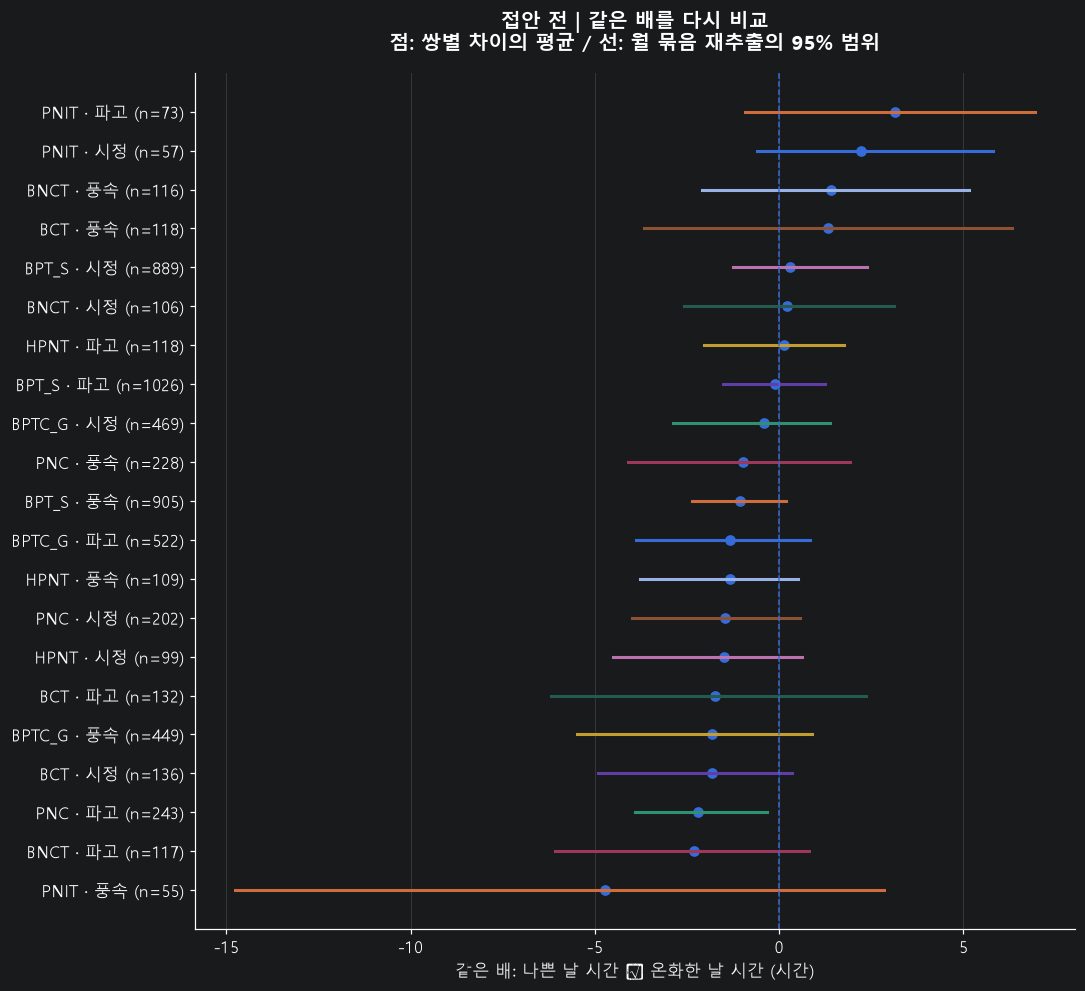

C:\Users\hjy42\AppData\Local\Temp\ipykernel_14268\3328658788.py:122: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.tight_layout()
C:\work\Port_Cast_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


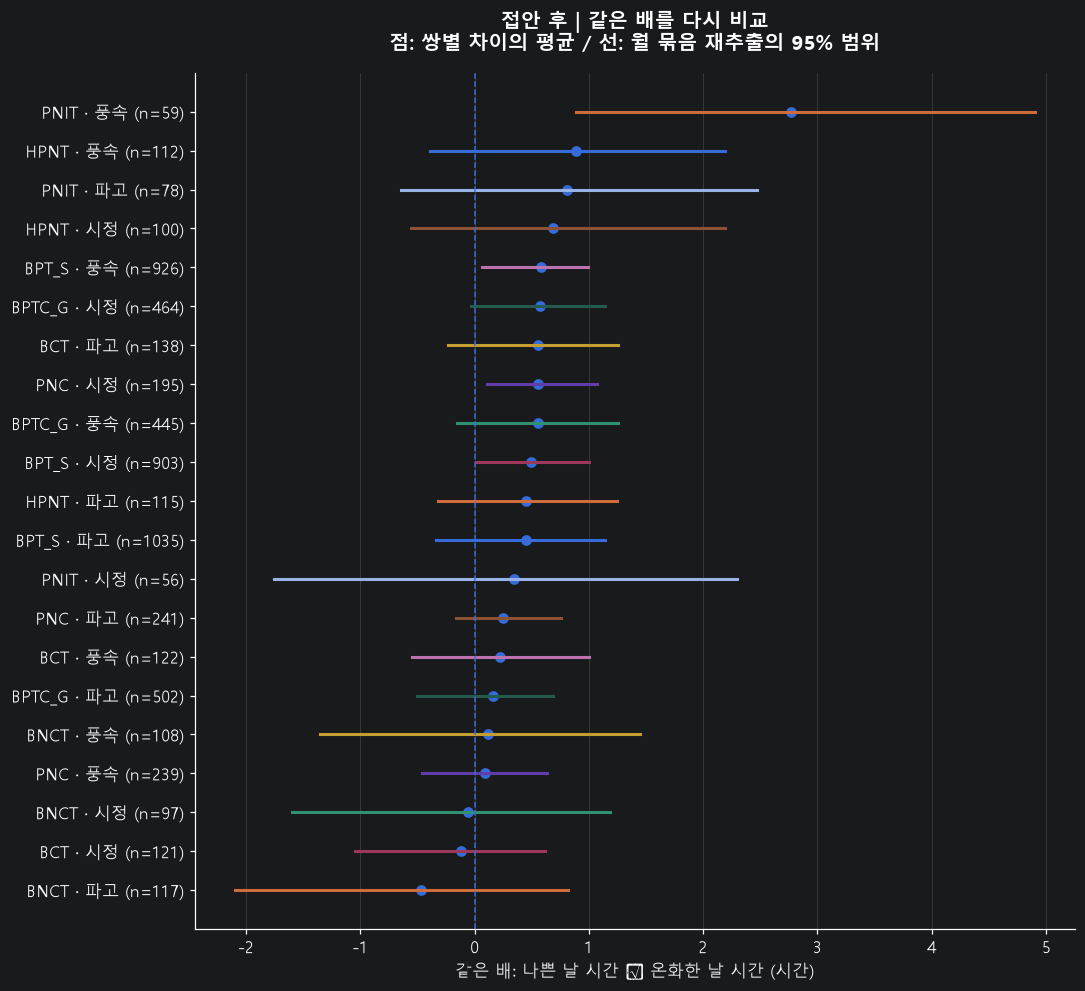

In [11]:
def paired_visits(data, phase, factor):
    cols = ["ship_key","terminal","work","gt",f"{phase}_{factor}", f"{phase}_h"]
    tmp = data.dropna(subset=cols).loc[data["work"].gt(0) & data["gt"].gt(0)].copy()
    stamp = "arrival" if phase == "pre" else "berth"
    pairs = []
    for (ship_key, terminal), g in tmp.groupby(["ship_key","terminal"]):
        bad = g.loc[g[f"{phase}_bad_{factor}"].fillna(False)].sort_values(stamp)
        normal = g.loc[g[f"{phase}_calm"] & ~g[f"{phase}_bad_{factor}"].fillna(False)].copy()
        if bad.empty or normal.empty: continue
        used = set()
        for idx, r in bad.iterrows():
            pool = normal.loc[~normal.index.isin(used)]
            if pool.empty: break
            distance = (pool[stamp]-r[stamp]).abs().dt.total_seconds()/86400
            work_ratio = pool["work"]/r["work"]
            gt_ratio = pool["gt"]/r["gt"]
            ok = (distance.le(180) & distance.gt(0)
                  & work_ratio.between(.8,1.25) & gt_ratio.between(.95,1.05)
                  & pool[f"{phase}_season"].eq(r[f"{phase}_season"]))
            candidates = pool.loc[ok]
            if candidates.empty: continue
            score = (work_ratio.loc[ok].apply(np.log).abs()/np.log(1.25)
                     + distance.loc[ok]/180)
            j = score.idxmin()
            ref = pool.loc[j]
            used.add(j)
            pairs.append({"terminal":terminal,"size":str(r["size"]),"phase":phase,"factor":factor,
                          "ship_key":ship_key,"bad_row":r["row_id"],"normal_row":ref["row_id"],
                          "bad_time":r[stamp],"normal_time":ref[stamp],
                          "bad_h":r[f"{phase}_h"],"normal_h":ref[f"{phase}_h"],
                          "delta_h":r[f"{phase}_h"]-ref[f"{phase}_h"],
                          "bad_work":r["work"],"normal_work":ref["work"],
                          "month_block":str(r[stamp].to_period("M")),
                          "year":r[stamp].year,
                          "very_long":bool(r["very_long"] or ref["very_long"])})
    return pd.DataFrame(pairs)

def month_block_interval(g):
    """월 단위 재추출. 비교쌍 차이의 평균 범위를 계산합니다."""
    n = len(g)
    blocks = g.groupby("month_block")["delta_h"].agg(["sum","size"])
    if n < 20 or len(blocks) < 6:
        return np.nan, np.nan
    rng = np.random.default_rng(SEED)
    sampled = rng.integers(0, len(blocks), size=(BOOTSTRAPS, len(blocks)))
    sums = blocks["sum"].to_numpy()[sampled].sum(axis=1)
    counts = blocks["size"].to_numpy()[sampled].sum(axis=1)
    return tuple(np.quantile(sums/counts, [.025,.975]))

pair_tables = [paired_visits(ships,p,f) for p in WEATHER for f in WEATHER[p]]
pairs = pd.concat([x for x in pair_tables if not x.empty], ignore_index=True) if any(not x.empty for x in pair_tables) else pd.DataFrame()
pair_summaries = []
if not pairs.empty:
    for (term, phase, factor), g in pairs.groupby(["terminal","phase","factor"]):
        low, high = month_block_interval(g)
        year_effects = g.groupby("year")["delta_h"].agg(["mean","size"])
        qualified = year_effects.loc[year_effects["size"].ge(5)]
        sensitivity = g.loc[~g["very_long"], "delta_h"]
        pair_summaries.append({"terminal":term,"phase":phase,"factor":factor,"pairs":len(g),
                               "ships":g["ship_key"].nunique(),"months":g["month_block"].nunique(),
                               "mean_delta":g["delta_h"].mean(),"median_delta":g["delta_h"].median(),
                               "ci_low":low,"ci_high":high,
                               "years_evaluable":len(qualified),"years_positive":int(qualified["mean"].gt(0).sum()),
                               "mean_without_30days":sensitivity.mean(),"pairs_without_30days":len(sensitivity)})
pair_summary = pd.DataFrame(pair_summaries)
keep_table("10_같은배_비교쌍", pairs)
keep_table("11_같은배_비교요약", pair_summary)
if not pair_summary.empty:
    display(pair_summary.round(2))
    for phase in WEATHER:
        sub = pair_summary.loc[pair_summary["phase"].eq(phase) & pair_summary["pairs"].ge(20)].copy()
        if sub.empty: continue
        sub["label"] = sub["terminal"]+" · "+sub["factor"]+" (n="+sub["pairs"].astype(str)+")"
        sub = sub.sort_values("mean_delta")
        fig, ax = plt.subplots(figsize=(10, max(5, .34*len(sub)+2)))
        ax.plot(sub["mean_delta"], np.arange(len(sub)), "o", markersize=6)
        for y, (_,r) in enumerate(sub.iterrows()):
            if pd.notna(r["ci_low"]):
                ax.plot([r["ci_low"],r["ci_high"]],[y,y], linewidth=2)
        ax.axvline(0, linestyle="--", linewidth=1)
        ax.set_yticks(range(len(sub)))
        ax.set_yticklabels(sub["label"])
        ax.set_xlabel("같은 배: 나쁜 날 시간 − 온화한 날 시간 (시간)")
        ax.set_title(f"{PHASE_NAME[phase]} | 같은 배를 다시 비교\n점: 쌍별 차이의 평균 / 선: 월 묶음 재추출의 95% 범위", pad=15, weight="bold")
        ax.grid(axis="x", alpha=.25)
        finish(fig, f"11_pairs_{phase}")
else:
    print("설정한 조건으로 연결할 같은 배 비교쌍이 없습니다.")

### 같은 배 비교 결과는 이렇게 읽습니다

점이 +2에 있으면 **조건을 맞춘 같은 배의 나쁜 날 방문이 평균 2시간 더 길었다**는 뜻입니다. 선이 -1부터 +5까지라면 자료를 다시 묶어 볼 때 결과가 흔들려, 증가라고 단정하기 어렵습니다.

`years_positive`는 5쌍 이상 비교한 연도 중 차이가 양수인 연도 수입니다. 한 해에만 크게 나타난 현상인지 확인하세요. `mean_without_30days`는 30일 초과 기록을 뺐을 때의 값입니다. 이 값의 부호가 바뀌면 긴 기록 몇 개에 결과가 좌우될 수 있습니다.

이런 비교를 여러 개 했다고 해서 가장 큰 값이 반드시 진짜 원인은 아닙니다. **터미널과 크기별 표본 수, 여러 해의 반복, 나머지 그림까지 함께 보는 것이 핵심입니다.**

표의 `pairs`는 비교쌍 수, `ships`는 서로 다른 선박 수, `mean_delta`는 평균 차이, `median_delta`는 중앙값 차이입니다. 평균은 모두 더해 개수로 나눈 값이고, 중앙값은 크기순으로 세웠을 때 가운데 값입니다. 아주 긴 기록 몇 개가 있으면 두 수가 다르게 나올 수 있습니다.

## 7. 앞에 남아 있던 배와 뒤에 온 배의 관계

급식실에 **이미 줄 선 사람이 많으면** 새로 온 사람도 오래 기다릴 수 있습니다. 배가 입항한 순간, 같은 터미널을 이용하는 표본 중 먼저 들어온 기록이 몇 개 남아 있었는지 셉니다.

세 값을 구분합니다. **먼저 입항했지만 미접안인 기록**, **접안했지만 아직 항만에서 출항하지 않은 기록**, **접안한 지 24시간이 넘었는데 아직 항만에서 출항하지 않은 기록**입니다. 마지막 두 값에는 이미 이안한 배가 포함될 수 있어 실제 선석 사용량이라고 부르지 않습니다.

자기 자신과 정확히 같은 시각에 들어온 다른 기록은 ‘먼저 온 배’에서 제외합니다. 기상 때문에 긴 접안 후 시간이 생겼다고 먼저 단정하지 않고, **앞선 표본 적체와 후속 소요시간이 함께 늘어나는지** 봅니다.

**연결할 개선안:** 앞선 적체가 많은 조건에서 후속 소요시간도 반복해서 길면, 입항 건수만 알리는 화면보다 **미접안·미출항 표본 수와 종료예정시각을 같이 알리는 화면**을 검토합니다. 이 비교만으로 특정 배가 다른 배를 지연시켰다고 증명할 수는 없습니다.

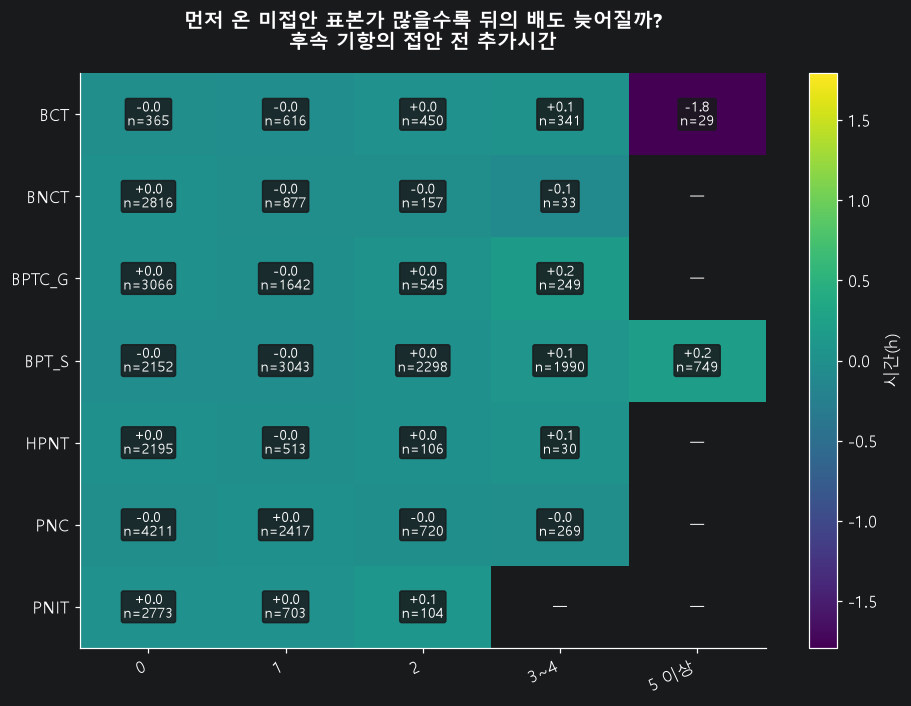

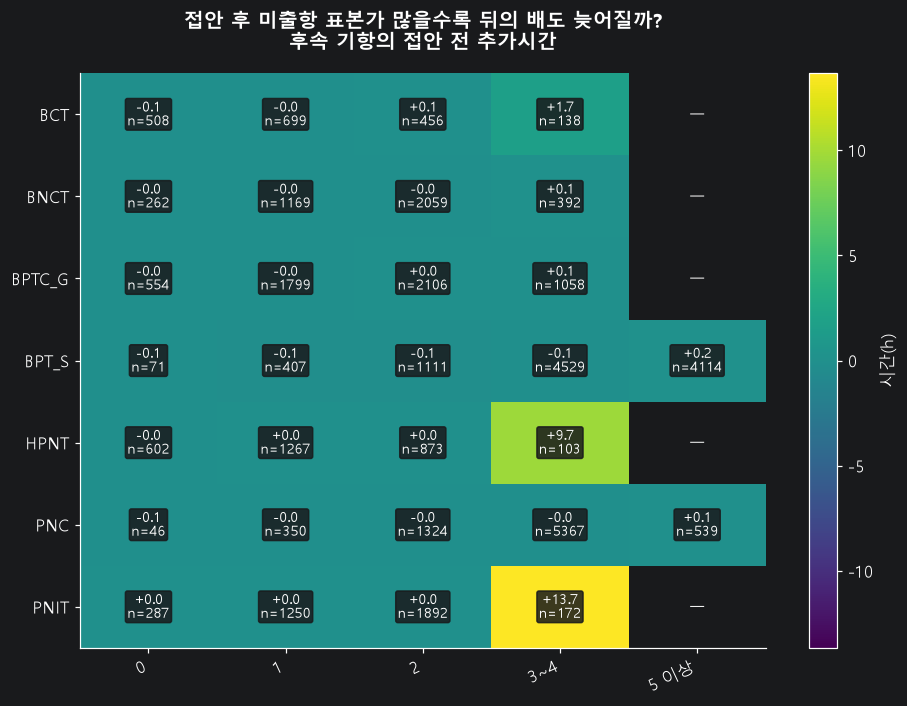

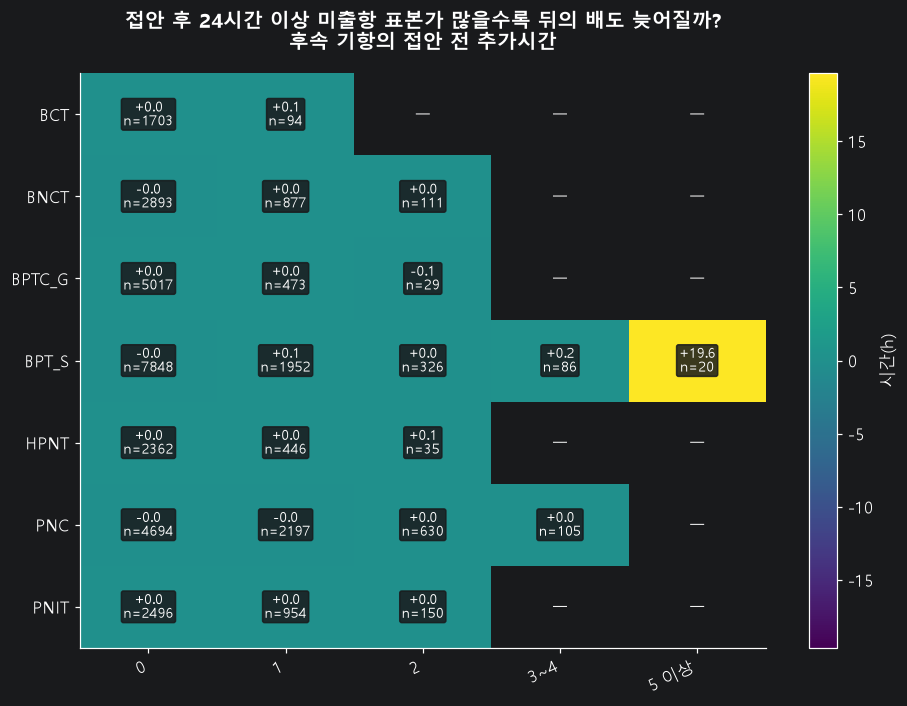

In [12]:
def active_count(starts, ends, queries, strictly_earlier=False):
    s = pd.to_datetime(starts).to_numpy(dtype="datetime64[ns]")
    e = pd.to_datetime(ends).to_numpy(dtype="datetime64[ns]")
    q = pd.to_datetime(queries).to_numpy(dtype="datetime64[ns]")
    good = (~np.isnat(s)) & (~np.isnat(e)) & (e>s)
    s, e = np.sort(s[good]), np.sort(e[good])
    side = "left" if strictly_earlier else "right"
    return np.searchsorted(s,q,side=side)-np.searchsorted(e,q,side="right")

for col in ["earlier_unberthed", "earlier_post_not_departed", "earlier_post_24h", "arrivals_prev24h"]:
    ships[col] = 0
for terminal, idx in ships.groupby("terminal").groups.items():
    pool = ships_all.loc[ships_all["terminal"].eq(terminal)]
    q = ships.loc[idx,"arrival"]
    ships.loc[idx,"earlier_unberthed"] = active_count(pool["arrival"],pool["berth"],q,True)
    ships.loc[idx,"earlier_post_not_departed"] = active_count(pool["berth"],pool["departure"],q,True)
    ships.loc[idx,"earlier_post_24h"] = active_count(pool["berth"]+pd.Timedelta(hours=24),pool["departure"],q,True)
    aa = np.sort(pool["arrival"].to_numpy(dtype="datetime64[ns]"))
    qq = q.to_numpy(dtype="datetime64[ns]")
    ships.loc[idx,"arrivals_prev24h"] = (np.searchsorted(aa,qq,side="left")
                                         - np.searchsorted(aa,qq-np.timedelta64(24,"h"),side="left"))
assert (ships[["earlier_unberthed","earlier_post_not_departed","earlier_post_24h"]] >= 0).all().all()

backlog_rows = []
for factor, label in [("earlier_unberthed","먼저 온 미접안 표본"),
                      ("earlier_post_not_departed","접안 후 미출항 표본"),
                      ("earlier_post_24h","접안 후 24시간 이상 미출항 표본")]:
    tmp = ships.copy()
    tmp["count_bin"] = pd.cut(tmp[factor], [-.1,0,1,2,4,np.inf], labels=["0", "1", "2", "3~4", "5 이상"])
    for (term, bin_name), g in tmp.groupby(["terminal","count_bin"],observed=True):
        supported = g["pre_excess"].dropna()
        backlog_rows.append({"terminal":term,"factor":factor,"factor_name":label,"count_bin":str(bin_name),
                             "n":len(g),"reference_n":len(supported),"median_pre_h":g["pre_h"].median(),
                             "p90_pre_h":g["pre_h"].quantile(.9),"median_excess":supported.median()})
backlog_effect = pd.DataFrame(backlog_rows)
keep_table("12_앞선적체와후속시간", backlog_effect)
for factor in backlog_effect["factor"].unique():
    g = backlog_effect.loc[backlog_effect["factor"].eq(factor)].copy()
    g.loc[g["reference_n"].lt(MIN_CELL),"median_excess"] = np.nan
    heatmap(g.pivot(index="terminal",columns="count_bin",values="median_excess").reindex(columns=["0","1","2","3~4","5 이상"]),
            f"{g['factor_name'].iloc[0]}가 많을수록 뒤의 배도 늦어질까?\n후속 기항의 접안 전 추가시간",f"12_backlog_{factor}",signed=True,
            counts=g.pivot(index="terminal",columns="count_bin",values="reference_n"))

## 8. 입항할 때는 괜찮았는데, 머무는 중에 특보가 시작됐을까?

학생이 학교에 올 때는 맑다가 수업 중에 비가 올 수 있습니다. 배도 **입항 시각의 날씨만 보면, 머무는 동안 시작된 특보를 놓칠 수 있습니다.**

이 단계는 파일에 있는 특보의 시작·종료 구간과 선박의 체류 구간을 실제로 겹쳐 봅니다. 겹치는 특보 구간은 합쳐 시간을 두 번 세지 않습니다. 파일의 특보구역은 두 항만에 공통으로 연결된 구역이며, 터미널 자체의 중단 기록은 아닙니다.

**아주 중요한 주의:** 오래 머문 배는 특보를 만날 기회도 더 많습니다. 따라서 ‘머무는 중 특보를 만난 배가 오래 있었다’는 표를 날씨의 원인 효과로 읽으면 안 됩니다. 여기서는 **입항 때만 분류해서 빠진 사례가 얼마나 되는지** 확인하는 용도입니다.

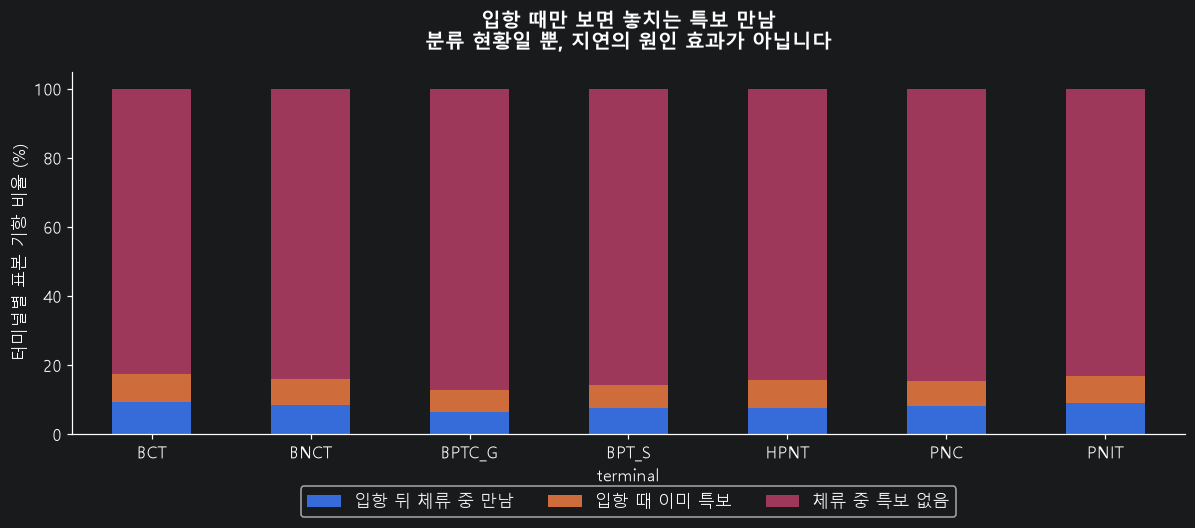

warning_encounter,입항 뒤 체류 중 만남,입항 때 이미 특보,체류 중 특보 없음
terminal,,,
BCT,202,173,1789
BNCT,348,301,3420
BPTC_G,373,361,4949
BPT_S,800,681,8865
HPNT,233,244,2557
PNC,628,556,6566
PNIT,346,286,3137


In [13]:
events = events_raw.copy()
for col in ["특보시작_KST","특보종료_KST"]:
    events[col] = pd.to_datetime(events[col],errors="coerce")
if events["예보구역코드"].dropna().nunique() > 1:
    raise ValueError("특보구역이 여러 개입니다. 항만과 구역의 연결을 확인한 뒤 사용해야 합니다.")
events = events.drop_duplicates("특보ID").dropna(subset=["특보시작_KST","특보종료_KST"])
events = events.loc[events["특보종료_KST"].gt(events["특보시작_KST"])].sort_values("특보시작_KST")
merged = []
for _, r in events.iterrows():
    a,b = r["특보시작_KST"], r["특보종료_KST"]
    typ = str(r["특보종류구성"])
    if merged and a <= merged[-1]["end"]:
        merged[-1]["end"] = max(b, merged[-1]["end"])
        merged[-1]["ids"].append(str(r["특보ID"]))
        merged[-1]["types"].add(typ)
    else:
        merged.append({"start":a,"end":b,"ids":[str(r["특보ID"])],"types":{typ}})
episodes = pd.DataFrame([{"episode":f"E{i+1:03d}","start":r["start"],"end":r["end"],
                          "source_ids":"/".join(r["ids"]),"type":"+".join(sorted(r["types"]))}
                         for i,r in enumerate(merged)])

def overlap_hours(starts, ends, event_table=episodes):
    a = pd.to_datetime(starts).to_numpy(dtype="datetime64[ns]")
    b = pd.to_datetime(ends).to_numpy(dtype="datetime64[ns]")
    out = np.zeros(len(a),dtype=float)
    for _, e in event_table.iterrows():
        left = np.maximum(a,np.datetime64(e["start"]))
        right = np.minimum(b,np.datetime64(e["end"]))
        out += np.maximum((right-left)/np.timedelta64(1,"h"),0)
    return out

ships["warning_at_arrival"] = False
for _, e in episodes.iterrows():
    ships.loc[ships["arrival"].ge(e["start"]) & ships["arrival"].lt(e["end"]),"warning_at_arrival"] = True
ships["stay_warning_h"] = overlap_hours(ships["arrival"],ships["departure"])
ships["pre_warning_overlap_h"] = overlap_hours(ships["arrival"],ships["berth"])
ships["post_warning_overlap_h"] = overlap_hours(ships["berth"],ships["departure"])
assert (ships["stay_warning_h"] <= ships["stay_h"]+1e-7).all()
assert np.allclose(ships["pre_warning_overlap_h"]+ships["post_warning_overlap_h"],ships["stay_warning_h"])
ships["warning_encounter"] = np.select(
    [ships["warning_at_arrival"], (~ships["warning_at_arrival"]) & ships["stay_warning_h"].gt(0)],
    ["입항 때 이미 특보", "입항 뒤 체류 중 만남"],default="체류 중 특보 없음")
encounter = pd.crosstab(ships["terminal"],ships["warning_encounter"])
keep_table("13_체류중특보_분류", encounter)
keep_table("14_통합특보사건", episodes)
fig, ax = plt.subplots(figsize=(11,5))
encounter.div(encounter.sum(axis=1),axis=0).mul(100).plot.bar(stacked=True,ax=ax,rot=0)
ax.set_ylabel("터미널별 표본 기항 비율 (%)")
ax.set_title("입항 때만 보면 놓치는 특보 만남\n분류 현황일 뿐, 지연의 원인 효과가 아닙니다",weight="bold",pad=15)
ax.legend(loc="upper center",bbox_to_anchor=(.5,-.12),ncol=3)
finish(fig,"13_warning_encounter")
display(encounter)

## 9. 특보가 끝난 뒤 입항과 미접안 표본은 언제까지 많을까?

이번에는 **특보 종료시각**을 0시간으로 놓고 4일(96시간)을 봅니다. 실제 항만 운영 재개시각은 이 파일만으로 알 수 없으므로 사용하지 않습니다.

공정한 비교를 위해 같은 터미널에서 같은 요일·같은 시각의 다른 날을 찾습니다. 기준일은 같은 해의 앞뒤 12주 이내이며, 전날부터 이후 4일까지 다른 특보가 겹치지 않은 날입니다. 기준일이 3개 이상일 때만 비교합니다. 특보가 이어지거나 분석창이 겹치는 사건은 제외합니다.

**막대가 +1이면:** 해당 6시간 동안 비교일보다 입항 기록이 평균 1건 많았다는 뜻입니다. **미접안 표본 차이가 +1이면:** 그 시점에 비교일보다 아직 접안하지 않은 표본이 평균 1척 더 남았다는 뜻입니다.

입항이 늘어도 미접안 표본이 늘지 않는다면, 처리할 수 있는 증가였을 수 있습니다. 둘 다 함께 늘고 오래 이어지면 종료 뒤 일정 조정을 검토할 근거가 됩니다.

관측이 시작되기 전·끝난 뒤, 기록이 너무 적은 달은 빼고 비교합니다. 월 10기항 이상 조건은 파일이 그 달을 어느 정도 담고 있는지 보는 최소 확인일 뿐, 전체 기항이 수집됐다는 보장은 아닙니다.

**터미널 간 순위로 읽지 마세요.** 터미널마다 관측기간과 선정된 특보 사건이 다릅니다. 특히 BCT는 관측 시작이 늦습니다. 각 터미널 내부의 비교일 대비 변화이며, 서로의 운영능력을 동일한 사건 조건으로 직접 평가한 순위는 아닙니다.

분석 사건 수는 '터미널×특보 종료' 단위입니다. 같은 특보가 여러 터미널에 등장합니다.


reason,관측 범위 또는 월 표본 부족,사용,종료 뒤 96시간에 다른 특보,특보 없는 비교일 3개 미만
terminal,,,,
BCT,72,49,22,1
BNCT,0,96,46,2
BPTC_G,0,96,46,2
BPT_S,0,96,46,2
HPNT,0,96,46,2
PNC,0,96,46,2
PNIT,0,96,46,2


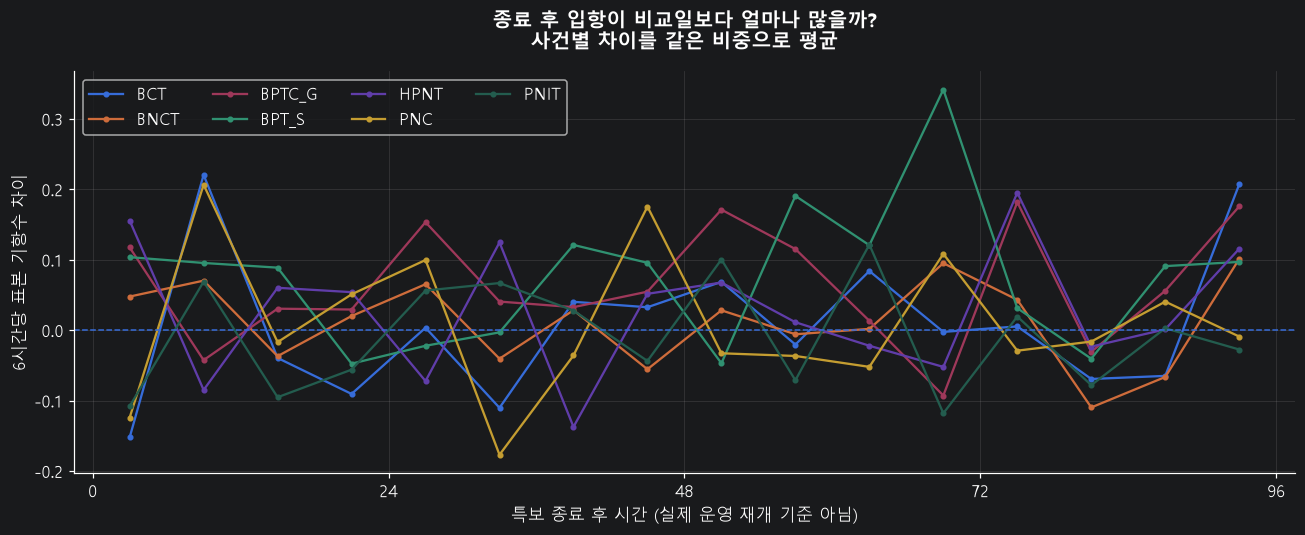

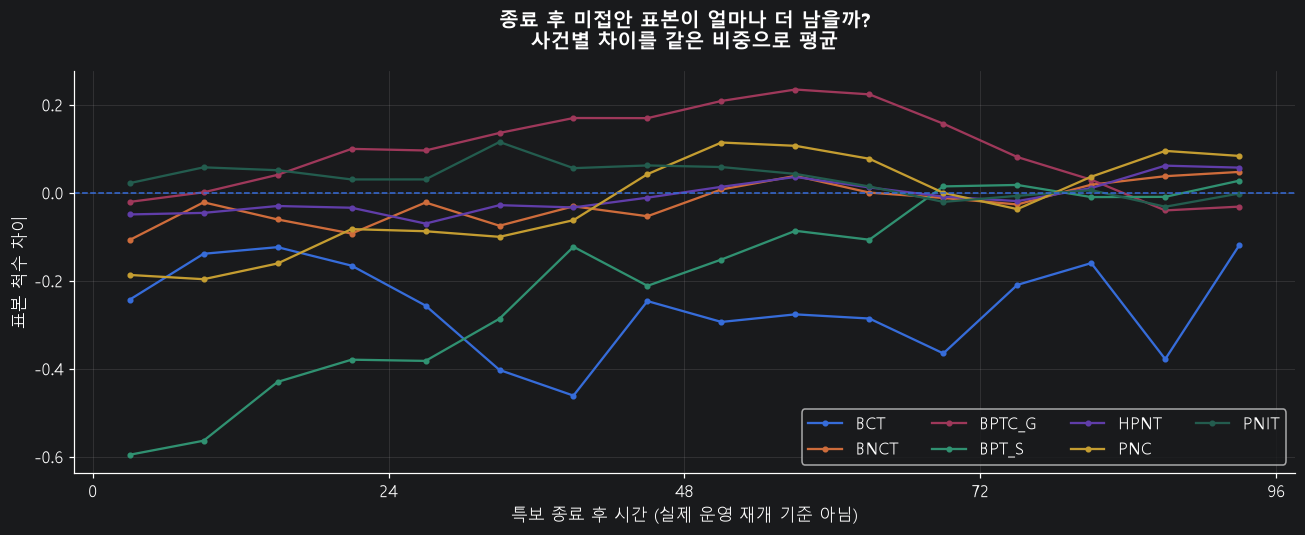

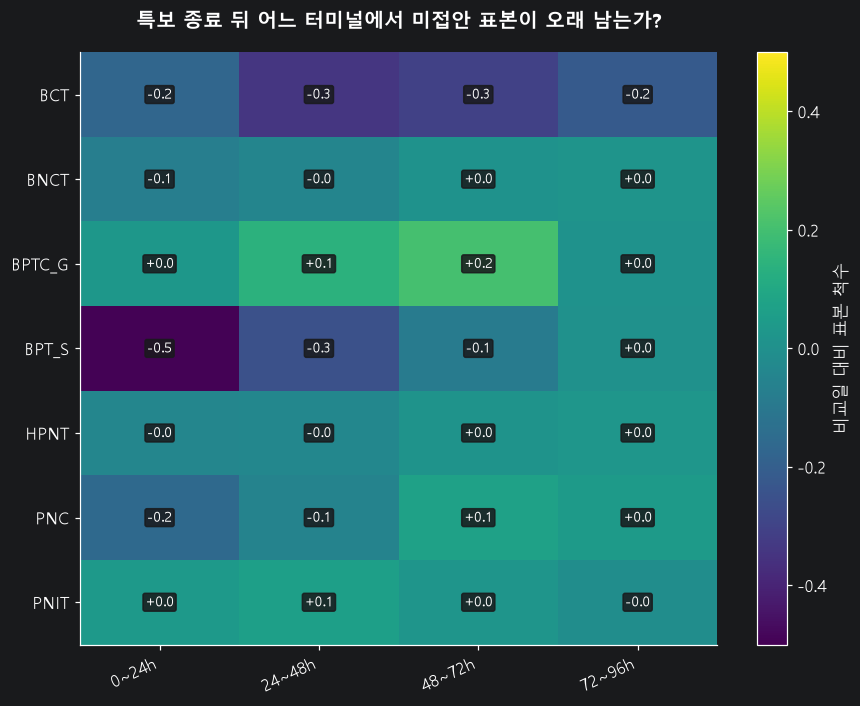

,terminal,episode,end,type,initial_n,remaining_0h,remaining_24h,remaining_48h,remaining_72h,remaining_96h,cohort90_h,cohort90_status
0,BCT,E073,2022-06-08 06:00:00,풍랑,0,0,0,0,0,0,NaN,초기 표본 3척 미만
1,BCT,E074,2022-06-14 22:00:00,풍랑,0,0,0,0,0,0,NaN,초기 표본 3척 미만
2,BCT,E075,2022-06-25 04:00:00,풍랑,0,0,0,0,0,0,NaN,초기 표본 3척 미만
3,BCT,E076,2022-08-02 01:00:00,풍랑,1,1,0,0,0,0,NaN,초기 표본 3척 미만
4,BCT,E080,2022-09-21 10:00:00,태풍/풍랑,2,2,1,1,1,0,NaN,초기 표본 3척 미만
5,BCT,E081,2022-10-08 21:00:00,풍랑,1,1,0,0,0,0,NaN,초기 표본 3척 미만
6,BCT,E082,2022-10-25 15:00:00,풍랑,0,0,0,0,0,0,NaN,초기 표본 3척 미만
7,BCT,E083,2022-11-30 11:00:00,풍랑,0,0,0,0,0,0,NaN,초기 표본 3척 미만
8,BCT,E084,2022-12-25 07:00:00,풍랑,0,0,0,0,0,0,NaN,초기 표본 3척 미만
9,BCT,E086,2023-01-16 06:00:00,풍랑,1,1,0,0,0,0,NaN,초기 표본 3척 미만


In [14]:
def any_warning(a,b):
    return bool(((episodes["start"]<b)&(episodes["end"]>a)).any())

# 터미널별 관측 기간. BCT처럼 늦게 나타난 터미널에 과거 0척을 만들지 않습니다.
coverage = {}
for term,g in ships_all.groupby("terminal"):
    counts = g.groupby(g["arrival"].dt.to_period("M")).size()
    coverage[term] = {"start":max(START,g["arrival"].min().normalize()+pd.Timedelta(days=1)),
                      "end":min(STOP,g["arrival"].max().normalize()),
                      "months":set(counts.index[counts.ge(10)])}

def covered(term,a,b):
    c = coverage[term]
    months = pd.period_range(a.to_period("M"),(b-pd.Timedelta(seconds=1)).to_period("M"),freq="M")
    return a >= c["start"] and b <= c["end"] and all(m in c["months"] for m in months)

def event_measure(pool, anchor):
    starts = anchor + pd.to_timedelta(np.arange(0,96,6),unit="h")
    ends = starts + pd.Timedelta(hours=6)
    aa = np.sort(pool["arrival"].to_numpy(dtype="datetime64[ns]"))
    counts = (np.searchsorted(aa,ends.to_numpy(),side="left")-np.searchsorted(aa,starts.to_numpy(),side="left"))
    mids = starts+pd.Timedelta(hours=3)
    stock = active_count(pool["arrival"],pool["berth"],mids)
    return counts.astype(float),stock.astype(float)

post_event_rows, recovery_rows, eligibility_rows = [], [], []
valid_episodes = episodes.loc[episodes["end"].ge(START) & episodes["end"].lt(STOP)].copy()
for term in TERMINALS:
    pool = ships_all.loc[ships_all["terminal"].eq(term)]
    previous_end = None
    for _,e in valid_episodes.sort_values("end").iterrows():
        t = e["end"]
        reason = "사용"
        if not covered(term,e["start"]-pd.Timedelta(hours=24),t+pd.Timedelta(hours=96)):
            reason = "관측 범위 또는 월 표본 부족"
        elif any_warning(t,t+pd.Timedelta(hours=96)):
            reason = "종료 뒤 96시간에 다른 특보"
        elif previous_end is not None and t < previous_end:
            reason = "선정 사례와 분석창 겹침"
        refs = []
        if reason == "사용":
            for weeks in list(range(-12,0))+list(range(1,13)):
                r = t+pd.Timedelta(weeks=weeks)
                if r.year != t.year: continue
                if not covered(term,r-pd.Timedelta(hours=24),r+pd.Timedelta(hours=96)): continue
                if any_warning(r-pd.Timedelta(hours=24),r+pd.Timedelta(hours=96)): continue
                refs.append(r)
            if len(refs)<3: reason = "특보 없는 비교일 3개 미만"
        eligibility_rows.append({"terminal":term,"episode":e["episode"],"end":t,"reason":reason,"reference_days":len(refs)})
        if reason != "사용": continue
        previous_end = t+pd.Timedelta(hours=96)
        actual_a,actual_q = event_measure(pool,t)
        reference = [event_measure(pool,r) for r in refs]
        ref_a = np.mean([x[0] for x in reference],axis=0)
        ref_q = np.mean([x[1] for x in reference],axis=0)
        for j,h in enumerate(range(0,96,6)):
            post_event_rows.append({"terminal":term,"episode":e["episode"],"type":e["type"],"year":t.year,
                                    "end":t,"hours":h+3,"reference_days":len(refs),
                                    "arrivals":actual_a[j],"reference_arrivals":ref_a[j],
                                    "arrival_diff":actual_a[j]-ref_a[j],"unberthed":actual_q[j],
                                    "reference_unberthed":ref_q[j],"unberthed_diff":actual_q[j]-ref_q[j]})
        initial = pool.loc[pool["arrival"].le(t) & pool["berth"].gt(t)]
        waits = (initial["berth"]-t).dt.total_seconds()/3600
        row = {"terminal":term,"episode":e["episode"],"end":t,"type":e["type"],"initial_n":len(initial)}
        for h in [0,24,48,72,96]: row[f"remaining_{h}h"] = int(waits.gt(h).sum())
        if len(waits)>=3:
            ordered = np.sort(waits.to_numpy())
            clear90 = ordered[int(np.ceil(.9*len(ordered)))-1]
            row["cohort90_h"] = clear90 if clear90<=96 else np.nan
            row["cohort90_status"] = "96시간 안에 도달" if clear90<=96 else "96시간 안에 미도달"
        else:
            row["cohort90_h"] = np.nan
            row["cohort90_status"] = "초기 표본 3척 미만"
        recovery_rows.append(row)
post_events = pd.DataFrame(post_event_rows)
cohort_recovery = pd.DataFrame(recovery_rows)
eligibility = pd.DataFrame(eligibility_rows)
keep_table("15_사건선정과제외",eligibility)
keep_table("16_특보종료후_6시간변화",post_events)
keep_table("17_종료시점미접안집단_접안까지",cohort_recovery)
print("분석 사건 수는 '터미널×특보 종료' 단위입니다. 같은 특보가 여러 터미널에 등장합니다.")
display(eligibility.groupby(["terminal","reason"]).size().unstack(fill_value=0))
if not post_events.empty:
    agg = post_events.groupby(["terminal","hours"])[["arrival_diff","unberthed_diff"]].mean().reset_index()
    for col,title,unit in [("arrival_diff","종료 후 입항이 비교일보다 얼마나 많을까?","6시간당 표본 기항수 차이"),
                           ("unberthed_diff","종료 후 미접안 표본이 얼마나 더 남을까?","표본 척수 차이")]:
        fig,ax = plt.subplots(figsize=(12,5))
        for term,g in agg.groupby("terminal"):
            ax.plot(g["hours"],g[col],marker="o",markersize=3,label=term)
        ax.axhline(0,linestyle="--",linewidth=1)
        ax.set_xticks([0,24,48,72,96])
        ax.set_xlabel("특보 종료 후 시간 (실제 운영 재개 기준 아님)")
        ax.set_ylabel(unit)
        ax.set_title(title+"\n사건별 차이를 같은 비중으로 평균",weight="bold",pad=15)
        ax.legend(ncol=4)
        ax.grid(alpha=.2)
        finish(fig,f"16_event_{col}")
    blocks = post_events.assign(day_window=(post_events["hours"]//24).astype(int).map({0:"0~24h",1:"24~48h",2:"48~72h",3:"72~96h"}))
    block_summary = blocks.groupby(["terminal","day_window"])["unberthed_diff"].mean().unstack()
    heatmap(block_summary.reindex(columns=["0~24h","24~48h","48~72h","72~96h"]),
            "특보 종료 뒤 어느 터미널에서 미접안 표본이 오래 남는가?", "17_event_stock_heat",unit="비교일 대비 표본 척수",signed=True)
    display(cohort_recovery.head(12))
else:
    print("깨끗한 비교창을 확보한 사건이 없습니다. 15_사건선정과제외 표를 확인하세요.")

### ‘회복’이라는 말도 두 가지로 구분합니다

`종료시점 미접안 집단`은 특보가 끝났을 때 이미 기다리던 배만 고정해 추적합니다. 90%가 접안했어도 새로 온 배가 쌓이면 터미널 전체가 회복된 것은 아닙니다.

반대로 `미접안 표본 차이`는 새로 들어오는 배까지 포함해 비교일보다 줄이 얼마나 더 남는지 봅니다. 두 지표를 함께 봐야 **기존 줄은 풀렸는데 새 줄이 생기는 경우**를 구분할 수 있습니다.

96시간 안에 90%가 접안하지 않았다면 ‘96시간 안에 미도달’로 남깁니다. 96시간이라고 임의로 잘라 회복시간 평균에 넣지 않습니다. 태풍 사건이 적으면 풍랑 사건의 평균과 같은 수준으로 일반화하지 않습니다.

**추가 자료 없이 가능한 결론:** ‘특보 종료 뒤 어느 터미널의 표본에서 1~3일간 추가 관찰과 일정 재확인이 필요해 보인다.’

**말하면 안 되는 결론:** ‘실제 작업 재개 후 48시간이면 모든 선석이 정상화된다.’

## 10. 정보를 더하면 다음 해 예측도 좋아질까?

연습문제를 잘 푸는 것만으로는 충분하지 않습니다. **처음 보는 시험문제도 잘 풀어야** 도움이 됩니다. 그래서 2020~2023년으로 연습하고 2024년을 시험지로 남겨 둡니다.

이번 시험은 **입항할 때, 접안까지 걸릴 시간을 예상하기**입니다.

| 방법 | 알고 있는 정보 |
|---|---|
| 단순 기준 | 그 터미널의 과거 접안 전 중앙시간 |
| A. 기본 정보 | 터미널, 총톤수, 월·요일·시각·연도 |
| B. 기본 + 날씨 | A + 입항 전 24시간 풍속·파고·시정·특보 노출 |
| C. 기본 + 날씨 + 표본 적체 | B + 먼저 온 미접안·미출항 기록, 직전 24시간 입항 기록 |

**작업량은 넣지 않습니다.** 파일의 작업량이 입항 전에 확정되어 있었는지 모르기 때문입니다. 체류 중 최대파고, 출항 때 날씨, 나중에 확인된 특보 최고수준도 넣지 않습니다. 학습 기록은 2024년 전에 접안이 끝난 기록만 사용합니다.

접안이 오래 걸린 배만 없애면 시험이 쉬워지므로 장기 기록도 유지합니다. **평균 오차가 작을수록 좋지만, 6시간 이상 걸린 배에서도 좋아지는지 따로 확인합니다.**

알고리즘은 여러 조건을 나누어 예측하는 나무 모델을 차례로 보완하는 방식입니다. 정확한 식을 외울 필요는 없습니다. 중요한 것은 **시험지로 연습하지 않는 것**입니다. 전처리도 학습자료에서만 결정합니다. 방법 참고: scikit-learn 공식 `Common pitfalls`와 `HistGradientBoostingRegressor` 문서(마지막 참고란).

> 이 검증은 현재 파일의 표본 안에서의 시험입니다. 먼저 온 배의 상태도 현재 파일로 과거를 재구성한 것이며, 실시간 데이터 수집 완전성까지 확인한 운영 시스템은 아닙니다. C가 좋더라도 기상이 원인이거나 일정 변경의 절감효과가 증명된 것은 아닙니다.

C:\Users\hjy42\AppData\Local\Temp\ipykernel_14268\1863995161.py:21: Pandas4Warning: Series.dt.weekday is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["weekday"] = data["arrival"].dt.weekday


,model,test_n,MAE_h,P90_error_h,MAE_when_wait6h_or_more
0,단순 기준,8149,4.732,14.600,25.503
1,A 기본,8149,4.059,11.412,25.066
2,B 날씨 추가,8149,4.046,11.316,25.178
3,C 표본적체 추가,8149,4.042,10.751,24.737


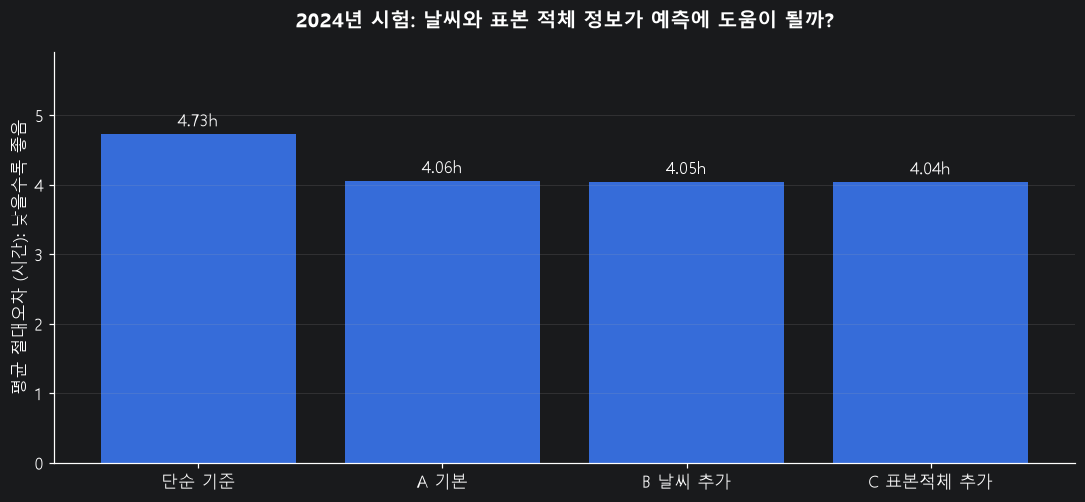

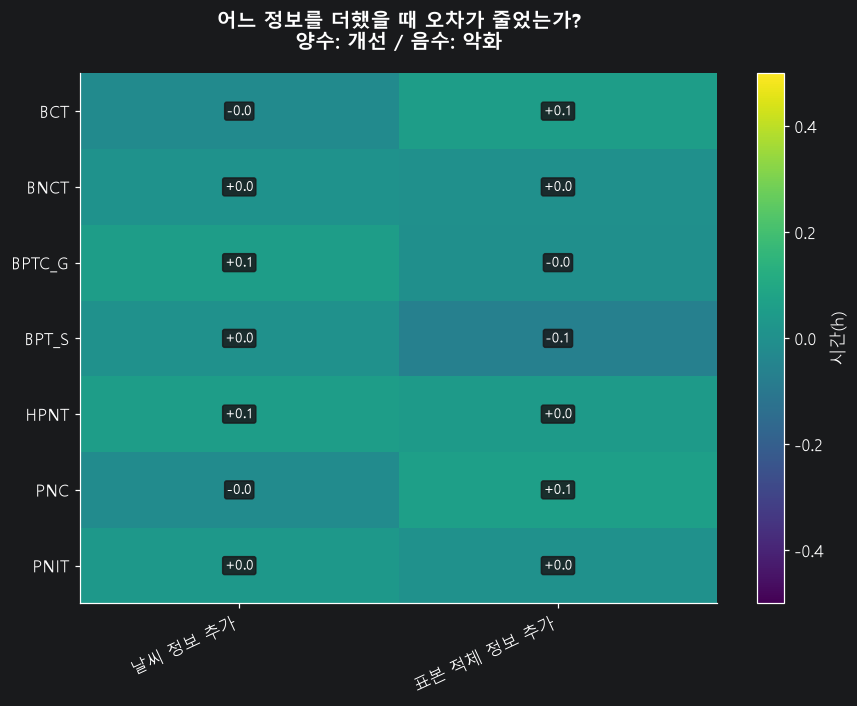

,terminal,n,weather_gain_h,load_gain_h,total_gain_h,total_gain_ci_low,total_gain_ci_high
0,BCT,989,-0.022,0.056,0.034,-0.042,0.097
1,BNCT,897,0.010,0.003,0.013,-0.019,0.039
2,BPTC_G,1158,0.056,-0.001,0.055,0.033,0.081
3,BPT_S,2246,0.005,-0.066,-0.061,-0.134,0.020
4,HPNT,685,0.058,0.046,0.104,0.057,0.148
5,PNC,1446,-0.016,0.065,0.049,0.016,0.094
6,PNIT,728,0.033,0.006,0.039,0.016,0.068


In [16]:
model_scores = pd.DataFrame()
model_by_terminal = pd.DataFrame()
prediction_details = pd.DataFrame()
model_gain = pd.DataFrame()
if RUN_PREDICTION:
    try:
        from sklearn.compose import ColumnTransformer
        from sklearn.pipeline import Pipeline
        from sklearn.preprocessing import OneHotEncoder
        from sklearn.impute import SimpleImputer
        from sklearn.ensemble import HistGradientBoostingRegressor
        from threadpoolctl import threadpool_limits
    except ImportError as exc:
        raise ImportError("예측 분석에는 scikit-learn이 필요합니다. %pip install scikit-learn을 실행하거나 RUN_PREDICTION=False로 두세요.") from exc
    data = ships.copy()
    data["log_gt"] = np.log1p(data["gt"].where(data["gt"].gt(0)))
    data["month_sin"] = np.sin(2*np.pi*data["arrival"].dt.month/12)
    data["month_cos"] = np.cos(2*np.pi*data["arrival"].dt.month/12)
    data["hour_sin"] = np.sin(2*np.pi*data["arrival"].dt.hour/24)
    data["hour_cos"] = np.cos(2*np.pi*data["arrival"].dt.hour/24)
    data["weekday"] = data["arrival"].dt.weekday
    data["calendar_year"] = data["arrival"].dt.year
    basic = ["log_gt","month_sin","month_cos","hour_sin","hour_cos","weekday","calendar_year"]
    weather_vars = ["pre_풍속","pre_파고","pre_시정",EXPOSURE["pre"]]
    load_vars = ["earlier_unberthed","earlier_post_not_departed","earlier_post_24h","arrivals_prev24h"]
    train = data.loc[data["arrival"].lt(TEST_START)&data["berth"].lt(TEST_START)].copy()
    test = data.loc[data["arrival"].ge(TEST_START)&data["arrival"].lt(STOP)&data["berth"].lt(STOP)].copy()
    if len(train)<200 or len(test)<50:
        print("학습 또는 시험 표본 부족: 예측 비교를 건너뜁니다.")
    else:
        pred = test[["row_id","terminal","size","arrival","pre_h"]].copy()
        simple = train.groupby("terminal")["pre_h"].median()
        pred["단순 기준"] = test["terminal"].map(simple)
        for name, nums in [("A 기본",basic), ("B 날씨 추가",basic+weather_vars),
                            ("C 표본적체 추가",basic+weather_vars+load_vars)]:
            try:
                encoder = OneHotEncoder(handle_unknown="ignore",sparse_output=False)
            except TypeError:
                encoder = OneHotEncoder(handle_unknown="ignore",sparse=False)
            prep = ColumnTransformer([
                ("numeric",SimpleImputer(strategy="median",add_indicator=True),nums),
                ("terminal",encoder,["terminal"])
            ])
            estimator = HistGradientBoostingRegressor(loss="absolute_error",max_iter=140,max_leaf_nodes=15,
                                                       min_samples_leaf=60,l2_regularization=1.0,
                                                       early_stopping=False,random_state=SEED)
            model = Pipeline([("prepare",prep),("predict",estimator)])
            with threadpool_limits(limits=2):
                model.fit(train[nums+["terminal"]],train["pre_h"])
                pred[name] = np.maximum(model.predict(test[nums+["terminal"]]),0)
        names = ["단순 기준","A 기본","B 날씨 추가","C 표본적체 추가"]
        scores, byterm = [], []
        for name in names:
            err = (pred[name]-pred["pre_h"]).abs()
            scores.append({"model":name,"test_n":int(err.notna().sum()),"MAE_h":err.mean(),
                           "P90_error_h":err.quantile(.9),
                           "MAE_when_wait6h_or_more":err.loc[pred["pre_h"].ge(LONG_WAIT_H)].mean()})
            for term,g in pred.groupby("terminal"):
                er = (g[name]-g["pre_h"]).abs()
                byterm.append({"terminal":term,"model":name,"n":len(g),"MAE_h":er.mean(),
                               "P90_error_h":er.quantile(.9)})
        model_scores = pd.DataFrame(scores)
        model_by_terminal = pd.DataFrame(byterm)
        prediction_details = pred
        keep_table("18_다음해예측_전체",model_scores)
        keep_table("19_다음해예측_터미널별",model_by_terminal)
        keep_table("20_2024예측명세",prediction_details)
        display(model_scores.round(3))
        fig,ax=plt.subplots(figsize=(10,4.7))
        bars=ax.bar(model_scores["model"],model_scores["MAE_h"])
        for b,v in zip(bars,model_scores["MAE_h"]):
            ax.annotate(f"{v:.2f}h",(b.get_x()+b.get_width()/2,v),xytext=(0,5),textcoords="offset points",ha="center")
        ax.set_ylim(0,max(model_scores["MAE_h"])*1.25)
        ax.set_ylabel("평균 절대오차 (시간): 낮을수록 좋음")
        ax.set_title("2024년 시험: 날씨와 표본 적체 정보가 예측에 도움이 될까?",weight="bold",pad=16)
        ax.grid(axis="y",alpha=.2)
        finish(fig,"18_prediction")
        gains = []
        for term,g in pred.groupby("terminal"):
            error_a = (g["A 기본"]-g["pre_h"]).abs()
            error_b = (g["B 날씨 추가"]-g["pre_h"]).abs()
            error_c = (g["C 표본적체 추가"]-g["pre_h"]).abs()
            z=pd.DataFrame({"delta_h":error_a-error_c,"month_block":g["arrival"].dt.to_period("M").astype(str)})
            lo,hi=month_block_interval(z)
            gains.append({"terminal":term,"n":len(g),"weather_gain_h":error_a.mean()-error_b.mean(),
                          "load_gain_h":error_b.mean()-error_c.mean(),"total_gain_h":error_a.mean()-error_c.mean(),
                          "total_gain_ci_low":lo,"total_gain_ci_high":hi})
        model_gain=pd.DataFrame(gains)
        keep_table("21_예측오차감소",model_gain)
        heatmap(model_gain.set_index("terminal")[["weather_gain_h","load_gain_h"]].rename(
                    columns={"weather_gain_h":"날씨 정보 추가","load_gain_h":"표본 적체 정보 추가"}),
                "어느 정보를 더했을 때 오차가 줄었는가?\n양수: 개선 / 음수: 악화", "19_prediction_gain",signed=True)
        display(model_gain.round(3))

### 예측 그림을 개선안으로 연결하기

C의 오차가 B보다 작고 긴 소요시간에서도 좋아지면, 날씨 경보만 띄우는 것보다 **현재 표본 적체를 함께 보여주는 정보 화면**이 유용할 가능성이 있습니다. 반대로 나아지지 않으면 복잡한 경보 시스템부터 만들 이유가 약합니다.

평균 오차가 1시간 줄었다고 **실제 대기가 1시간 줄어든 것은 아닙니다.** 예측이 나아진 것과 운영이 나아진 것은 다른 결과입니다. 특정 터미널에서만 나빠지면 전체 평균에 숨기지 말고 그 터미널 적용을 보류하세요.

## 11. 접안 순서를 바꾸는 가상 줄서기 실험

**급식 배식대가 1개, 2개, 3개라고 각각 가정하고 줄서는 순서를 바꾸어 봅니다.** 이 숫자는 실제 터미널 선석 수가 아닙니다.

| 비교 규칙 | 쉬운 설명 |
|---|---|
| 먼저 온 순서 | 먼저 도착한 배부터 처리 |
| 짧은 예상시간 우선 | 예상 처리가 짧은 배부터 처리 |
| 오래 기다린 배 보호 | 12시간 이상 기다린 배가 있으면 먼저, 아니면 짧은 예상시간 우선 |

현재 파일의 2024년 특보 종료 사례 중, 앞에서 깨끗한 비교창을 확보했고 대상 배가 10기항 이상인 경우를 사용합니다. 종료 시점의 미접안 배와 이후 72시간 입항한 배를 대상으로 합니다. 기항이 여러 실험에 중복되면 시나리오 결과를 실제 연간 절감시간으로 합산하지 않습니다.

처리시간은 **2024년 이전의 같은 터미널·크기·작업량에서 얻은 접안 후 시간 중앙값**을 대리값으로 사용합니다. 실제 순수 작업시간이 아니므로, 0.75배·1배·1.25배도 시험합니다. 해당 방문의 실제 작업량을 알고 재현하는 **사후 실험**이며, 입항 전 계획을 그대로 실행한 결과가 아닙니다.

> **강한 가정:** 가상 처리창구는 시작할 때 모두 비어 있고, 선박 호환성·수심·실제 선석 길이·도선·예선·장비·인력·새로운 작업 중단은 고려하지 않습니다. 이미 접안한 배가 가상 창구를 차지하는 상황도 넣지 않습니다. 따라서 이것은 **실제 재개 운항을 재현한 시뮬레이터가 아니라 순서 규칙의 장단점을 배우는 가상 실험**입니다. 숫자를 실제 절감시간·시설 소요·안전한 운영안으로 발표하면 안 됩니다.

평균 대기만 줄었는지 보지 말고, **90백분위 대기와 큰 배의 대기가 늘지는 않았는지** 함께 보세요. 90백분위는 10척 중 9척이 그 시간 안에 들어가는 수준이라는 뜻입니다.

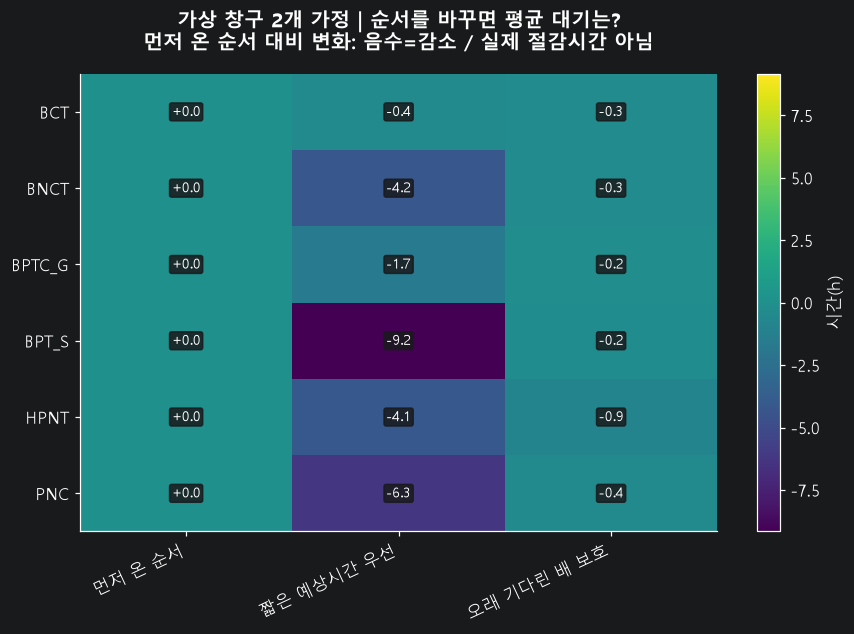

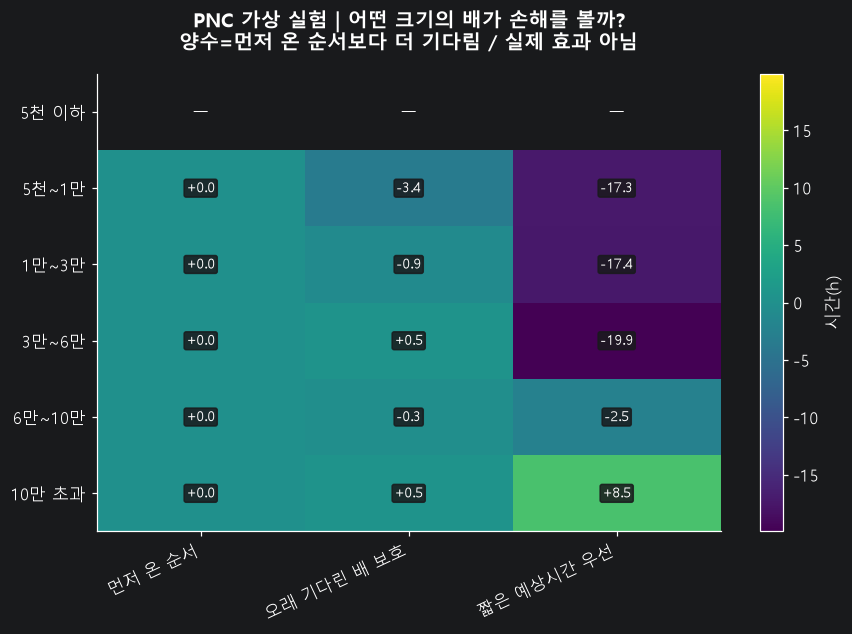

,terminal,servers,scale,policy,scenarios,mean_wait_h,mean_change_h,mean_p90_wait_h,mean_worse_jobs
0,BCT,1,0.75,먼저 온 순서,15,15.51,0.00,26.56,0.00
1,BCT,1,0.75,오래 기다린 배 보호,15,14.80,-0.71,26.28,1.13
2,BCT,1,0.75,짧은 예상시간 우선,15,12.73,-2.79,28.33,2.27
3,BCT,1,1.00,먼저 온 순서,15,25.36,0.00,43.63,0.00
4,BCT,1,1.00,오래 기다린 배 보호,15,25.02,-0.34,43.81,0.80
5,BCT,1,1.00,짧은 예상시간 우선,15,19.79,-5.57,41.86,2.40
6,BCT,1,1.25,먼저 온 순서,15,36.17,0.00,61.85,0.00
7,BCT,1,1.25,오래 기다린 배 보호,15,35.80,-0.37,61.85,0.60
8,BCT,1,1.25,짧은 예상시간 우선,15,27.93,-8.24,60.80,2.60
9,BCT,2,0.75,먼저 온 순서,15,4.24,0.00,10.05,0.00


In [17]:
simulation_jobs = pd.DataFrame()
simulation_cases = pd.DataFrame()
simulation_effect = pd.DataFrame()
if RUN_TOY_SIMULATION and not post_events.empty:
    training = ships.loc[ships["departure"].lt(TEST_START)&ships["post_h"].gt(0)].copy()
    lookup_tables = []
    for keys, minimum in [(["terminal","size","work_band"],12),(["terminal","size"],20),(["terminal"],40)]:
        tab=training.groupby(keys,observed=True)["post_h"].agg(["median","size"])
        # 집계의 size 열과 원본 크기 열은 인덱스에서 구분됩니다.
        tab=tab.loc[tab["size"].ge(minimum)]
        lookup_tables.append((keys,{k if isinstance(k,tuple) else (k,):float(v) for k,v in tab["median"].items()}))
    def duration_proxy(row):
        for keys,lookup in lookup_tables:
            key=tuple(row[k] for k in keys)
            if key in lookup: return lookup[key]
        return np.nan

    def queue_replay(jobs, servers, policy, scale=1.0):
        """실제 항만 운영이 아닌, 고정 처리시간을 갖는 가상 다중 창구 실험."""
        release=jobs["release_h"].to_numpy(float)
        duration=jobs["proxy_h"].to_numpy(float)*scale
        prior=jobs["prior_wait_h"].to_numpy(float)
        original=release-prior
        remaining=np.ones(len(jobs),dtype=bool)
        machines=[(0.0,k) for k in range(servers)]
        heapq.heapify(machines)
        result=[]
        for _ in range(len(jobs)):
            ready_at,server=heapq.heappop(machines)
            pending=np.flatnonzero(remaining)
            now=max(ready_at,float(release[pending].min()))
            eligible=pending[release[pending]<=now+1e-9]
            if policy=="먼저 온 순서":
                chosen=min(eligible,key=lambda k:(original[k],k))
            elif policy=="오래 기다린 배 보호" and np.any(now-release[eligible]+prior[eligible]>=FAIR_WAIT_H):
                protected=eligible[now-release[eligible]+prior[eligible]>=FAIR_WAIT_H]
                chosen=min(protected,key=lambda k:(original[k],k))
            else:
                chosen=min(eligible,key=lambda k:(duration[k],original[k],k))
            wait=max(now-release[chosen],0)+prior[chosen]
            finish_at=now+duration[chosen]
            result.append({"row_id":int(jobs.iloc[chosen]["row_id"]),"size":str(jobs.iloc[chosen]["size"]),
                           "wait_h":wait,"completion_h":finish_at,"duration_h":duration[chosen]})
            remaining[chosen]=False
            heapq.heappush(machines,(finish_at,server))
        assert len(result)==len(jobs) and len({r["row_id"] for r in result})==len(jobs)
        return result

    cases=post_events.loc[post_events["year"].eq(2024),["terminal","episode","end"]].drop_duplicates()
    jobs_rows=[]
    for _,e in cases.iterrows():
        term,t=e["terminal"],e["end"]
        g=ships.loc[ships["terminal"].eq(term)]
        mask=(g["arrival"].le(t)&g["berth"].gt(t)) | (g["arrival"].gt(t)&g["arrival"].lt(t+pd.Timedelta(hours=72)))
        jobs=g.loc[mask].copy().sort_values("arrival")
        if len(jobs)<10: continue
        jobs["proxy_h"]=jobs.apply(duration_proxy,axis=1)
        # 일부만 빼서 실험이 유리해지지 않도록 모든 기항의 대리시간이 있는 사례만 사용합니다.
        if jobs["proxy_h"].isna().any() or jobs["proxy_h"].le(0).any(): continue
        offset=(jobs["arrival"]-t).dt.total_seconds()/3600
        jobs["release_h"]=offset.clip(lower=0)
        jobs["prior_wait_h"]=(-offset).clip(lower=0)
        for servers in SIMULATED_SERVERS:
            for scale in SIMULATED_DURATION_SCALES:
                for policy in ["먼저 온 순서","짧은 예상시간 우선","오래 기다린 배 보호"]:
                    res=queue_replay(jobs,servers,policy,scale)
                    for r in res:
                        r.update(terminal=term,episode=e["episode"],servers=servers,scale=scale,policy=policy)
                    jobs_rows.extend(res)
    simulation_jobs=pd.DataFrame(jobs_rows)
    if not simulation_jobs.empty:
        base=simulation_jobs.loc[simulation_jobs["policy"].eq("먼저 온 순서"),
                                 ["terminal","episode","servers","scale","row_id","wait_h"]].rename(columns={"wait_h":"fcfs_wait_h"})
        simulation_jobs=simulation_jobs.merge(base,on=["terminal","episode","servers","scale","row_id"],how="left",validate="many_to_one")
        simulation_jobs["change_h"]=simulation_jobs["wait_h"]-simulation_jobs["fcfs_wait_h"]
        simulation_cases=simulation_jobs.groupby(["terminal","episode","servers","scale","policy"]).agg(
            jobs=("row_id","size"),mean_wait_h=("wait_h","mean"),p90_wait_h=("wait_h",lambda s:s.quantile(.9)),
            mean_change_h=("change_h","mean"),worse_jobs=("change_h",lambda s:int(s.gt(.01).sum()))).reset_index()
        simulation_effect=simulation_cases.groupby(["terminal","servers","scale","policy"]).agg(
            scenarios=("episode","nunique"),mean_wait_h=("mean_wait_h","mean"),mean_change_h=("mean_change_h","mean"),
            mean_p90_wait_h=("p90_wait_h","mean"),mean_worse_jobs=("worse_jobs","mean")).reset_index()
        keep_table("22_가상실험_개별기항",simulation_jobs)
        keep_table("23_가상실험_사건별",simulation_cases)
        keep_table("24_가상실험_요약",simulation_effect)
        show=simulation_effect.loc[simulation_effect["servers"].eq(2)&simulation_effect["scale"].eq(1)]
        mat=show.pivot(index="terminal",columns="policy",values="mean_change_h").reindex(
            columns=["먼저 온 순서","짧은 예상시간 우선","오래 기다린 배 보호"])
        heatmap(mat,"가상 창구 2개 가정 | 순서를 바꾸면 평균 대기는?\n먼저 온 순서 대비 변화: 음수=감소 / 실제 절감시간 아님",
                "20_toy_queue",signed=True)
        size_show=simulation_jobs.loc[simulation_jobs["servers"].eq(2)&simulation_jobs["scale"].eq(1)&simulation_jobs["terminal"].eq(TARGET_TERMINAL)]
        if not size_show.empty:
            ss=size_show.groupby(["size","policy"])["change_h"].agg(mean="mean", n="size").reset_index()
            heatmap(ss.pivot(index="size",columns="policy",values="mean").reindex(index=GT_LABELS),
                    f"{TARGET_TERMINAL} 가상 실험 | 어떤 크기의 배가 손해를 볼까?\n양수=먼저 온 순서보다 더 기다림 / 실제 효과 아님",
                    "21_toy_fairness",signed=True)
        display(simulation_effect.head(18).round(2))
    else:
        print("조건을 충족한 2024년 가상 실험 사례가 없습니다.")

### 이 실험에서 실제로 얻을 수 있는 것

‘짧은 예상시간 우선’이 평균 대기를 줄여도 큰 배나 오래 기다린 배에게 손해를 줄 수 있습니다. ‘오래 기다린 배 보호’는 그 단점을 줄이려는 규칙입니다. **어느 하나가 무조건 최고라는 결론을 미리 정하지 않습니다.**

창구 수를 1개에서 3개로 바꾸거나 처리시간 대리값을 바꾸었을 때 결과가 뒤집히면, 순서 변경의 장점도 가정에 민감합니다. 상세 표에서 `servers`와 `scale`별로 함께 확인하세요.

현재 파일만으로 제안할 수 있는 것은 **“이 접안 순서 규칙을 우선 검토할 가치가 있는가?”**까지입니다. ‘선석을 2개 운영하면 몇 시간 절감된다’거나 ‘이 순서를 즉시 현장 적용하자’는 결론은 이 실험의 범위를 넘습니다.

## 12. 터미널별 개선 후보를 한 장으로 정리하기

이제 여러 그림을 모읍니다. **점수 하나로 터미널을 줄 세우지 않습니다.** 표본 수, 같은 배 비교, 특보 종료 뒤 미접안 변화, 다음 해 예측 개선을 함께 보여줍니다.

같은 배 비교에서 20쌍 이상·6개월 묶음 이상이고, 여러 해에 양의 차이가 관측되며 재추출 범위가 0보다 큰 경우만 ‘추가 검토 신호’로 적습니다. 여러 비교 중 우연히 큰 값이 나올 수 있으므로 이것도 원인 확정이나 통계적 발견 선언은 아닙니다.

BCT는 앞선 분석에서 시각 정의 확인이 필요했던 터미널입니다. 추가 원자료가 없으므로 긴 접안 전 시간의 원인을 현장 문제로 확정하지 않고, **기록 정의 확인 보류 표시**를 남깁니다.

| 관찰되는 모습 | 추가 자료 없이 작성할 수 있는 제안 |
|---|---|
| 종료 뒤 입항 증가와 미접안 증가가 함께 반복 | 종료 뒤 1~3일간 일정 재확인·상황 공유의 우선 적용 후보 |
| 같은 배의 접안 후 시간 차이가 반복 | 기상조건별 종료예정시각 갱신안을 검토할 후보 |
| 날씨보다 표본 적체 정보를 넣을 때 예측이 개선 | 날씨만 알리는 화면보다 표본 적체를 함께 보여주는 화면 |
| 짧은 작업 우선 규칙이 큰 배에 큰 손해 | 단순 크기 우선이 아닌 장기 대기 보호 규칙도 비교 |
| 표본 부족, 여러 해 결과 불일치, 시각 정의 불확실 | 개선 대상 확정 보류. ‘자료로 판단 불가’도 결과 |

In [18]:
proposal_rows=[]
for term in TERMINALS:
    r={"터미널":term,"표본기항수":int(ships["terminal"].eq(term).sum()),
       "기록주의":"접안 전 기록 정의 확인 보류" if term=="BCT" else "예정·실제 시각 혼재 완전 분리 불가"}
    signals=[]
    for phase in WEATHER:
        label=PHASE_NAME[phase]
        qualified=pd.DataFrame()
        if not pair_summary.empty:
            qualified=pair_summary.loc[pair_summary["terminal"].eq(term)&pair_summary["phase"].eq(phase)
                                       &pair_summary["pairs"].ge(20)&pair_summary["months"].ge(6)
                                       &pair_summary["ci_low"].gt(0)&pair_summary["years_positive"].ge(2)]
        if qualified.empty:
            r[f"같은배_{label}_신호"]="일관된 증가 신호 미확보"
        else:
            best=qualified.sort_values("mean_delta",ascending=False).iloc[0]
            r[f"같은배_{label}_신호"]=f"{best['factor']} +{best['mean_delta']:.1f}h / {int(best['pairs'])}쌍 (탐색)"
            if not (term=="BCT" and phase=="pre"):
                signals.append("접안 일정 재확인" if phase=="pre" else "접안 후 종료예정시각 갱신 검토")
    if not post_events.empty:
        g=post_events.loc[post_events["terminal"].eq(term)]
        r["특보종료_비교사건수"]=g["episode"].nunique()
        for a,b in [(0,24),(24,48),(48,72)]:
            r[f"종료{a}~{b}h_추가미접안표본"]=g.loc[g["hours"].ge(a)&g["hours"].lt(b),"unberthed_diff"].mean()
        if len(g) and g.loc[g["hours"].lt(24),"unberthed_diff"].mean()>.5:
            signals.append("특보 종료 뒤 첫날 표본 적체 관찰 강화")
    if not model_gain.empty:
        g=model_gain.loc[model_gain["terminal"].eq(term)]
        if len(g):
            z=g.iloc[0]
            r["날씨추가_예측오차감소_h"]=z["weather_gain_h"]
            r["적체추가_예측오차감소_h"]=z["load_gain_h"]
            if z["load_gain_h"]>.05 and z["total_gain_ci_low"]>0:
                signals.append("표본 적체를 포함한 예상접안시간 화면 검토")
    r["개선안_검토방향"]=" / ".join(dict.fromkeys(signals)) if signals else "추가 자료 없이 특정 개선안의 효과를 확정하기 어려움"
    proposal_rows.append(r)
proposals=pd.DataFrame(proposal_rows)
keep_table("25_터미널별_개선후보",proposals)
display(proposals.round(2))

# 가상 실험의 가정 변화에 따라 결과가 달라지는지 확인하는 표
if not simulation_effect.empty:
    sensitivity=simulation_effect.groupby(["terminal","policy"]).agg(
        가정조합수=("mean_change_h","size"),평균대기개선조합수=("mean_change_h",lambda s:int(s.lt(0).sum())),
        가장작은변화_h=("mean_change_h","min"),가장큰변화_h=("mean_change_h","max")).reset_index()
    display(keep_table("26_가상실험_가정민감도",sensitivity).round(2))
print("이 표는 개선안의 검토 후보입니다. 실제 절감효과나 안전 운항 기준은 아닙니다.")

,터미널,표본기항수,기록주의,같은배_접안 전_신호,같은배_접안 후_신호,특보종료_비교사건수,종료0~24h_추가미접안표본,종료24~48h_추가미접안표본,종료48~72h_추가미접안표본,날씨추가_예측오차감소_h,적체추가_예측오차감소_h,개선안_검토방향
0,BCT,2164,접안 전 기록 정의 확인 보류,일관된 증가 신호 미확보,일관된 증가 신호 미확보,49,-0.17,-0.34,-0.31,-0.02,0.06,추가 자료 없이 특정 개선안의 효과를 확정하기 어려움
1,BNCT,4069,예정·실제 시각 혼재 완전 분리 불가,일관된 증가 신호 미확보,일관된 증가 신호 미확보,96,-0.07,-0.05,0.01,0.01,0.00,추가 자료 없이 특정 개선안의 효과를 확정하기 어려움
2,BPTC_G,5683,예정·실제 시각 혼재 완전 분리 불가,일관된 증가 신호 미확보,일관된 증가 신호 미확보,96,0.03,0.14,0.21,0.06,-0.00,추가 자료 없이 특정 개선안의 효과를 확정하기 어려움
3,BPT_S,10346,예정·실제 시각 혼재 완전 분리 불가,일관된 증가 신호 미확보,풍속 +0.6h / 926쌍 (탐색),96,-0.49,-0.25,-0.08,0.00,-0.07,접안 후 종료예정시각 갱신 검토
4,HPNT,3034,예정·실제 시각 혼재 완전 분리 불가,일관된 증가 신호 미확보,일관된 증가 신호 미확보,96,-0.04,-0.04,0.01,0.06,0.05,추가 자료 없이 특정 개선안의 효과를 확정하기 어려움
5,PNC,7750,예정·실제 시각 혼재 완전 분리 불가,일관된 증가 신호 미확보,시정 +0.6h / 195쌍 (탐색),96,-0.16,-0.05,0.07,-0.02,0.06,접안 후 종료예정시각 갱신 검토 / 표본 적체를 포함한 예상접안시간 화면 검토
6,PNIT,3769,예정·실제 시각 혼재 완전 분리 불가,일관된 증가 신호 미확보,풍속 +2.8h / 59쌍 (탐색),96,0.04,0.07,0.02,0.03,0.01,접안 후 종료예정시각 갱신 검토


,terminal,policy,가정조합수,평균대기개선조합수,가장작은변화_h,가장큰변화_h
0,BCT,먼저 온 순서,9,0,0.00,0.00
1,BCT,오래 기다린 배 보호,9,8,-0.71,0.00
2,BCT,짧은 예상시간 우선,9,9,-8.24,-0.00
3,BNCT,먼저 온 순서,9,0,0.00,0.00
4,BNCT,오래 기다린 배 보호,9,9,-0.87,-0.08
5,BNCT,짧은 예상시간 우선,9,9,-26.96,-0.10
6,BPTC_G,먼저 온 순서,9,0,0.00,0.00
7,BPTC_G,오래 기다린 배 보호,9,9,-0.41,-0.02
8,BPTC_G,짧은 예상시간 우선,9,9,-16.13,-0.02
9,BPT_S,먼저 온 순서,9,0,0.00,0.00


이 표는 개선안의 검토 후보입니다. 실제 절감효과나 안전 운항 기준은 아닙니다.


## 13. 저장, 보고서 작성, 이어서 분석하기

맨 위 `SAVE_OUTPUTS=True`로 실행하면 `부산항_추가분석_결과` 폴더에 표(CSV)와 그림(PNG)이 저장됩니다. CSV는 엑셀에서 한글이 보이도록 UTF-8 BOM 형식을 사용합니다. 원본 엑셀은 수정하지 않습니다.

### 보고서에 쓸 수 있는 문장 틀

**사실:** “관측된 표본에서 A 터미널의 풍속 악화 조건과 접안 후 시간 증가가 함께 나타났다.”  
**보완 확인:** “같은 배·같은 터미널·비슷한 작업량의 방문을 비교해도 같은 방향인지 확인했다.”  
**개선 후보:** “종료예정시각 갱신과 특보 종료 후 일정 재확인을 우선 검토한다.”  
**한계:** “순수 하역시간과 실제 운영 재개시각은 없어 설비 부족이나 실제 절감시간은 확정하지 않았다.”

### 이번 파일에서 일부러 하지 않은 일

실제 선석 수를 추측해서 넣기, 관측되지 않은 날씨를 0으로 채우기, 비용·매출 절감액 꾸며내기, GT만으로 안전 운항 가능 여부 정하기, 특보 종료를 실제 작업 재개로 바꾸어 부르기를 하지 않았습니다.

### 다음에 코드 셀을 추가할 때 쓸 변수

`ships`: 정리한 기항 기록 / `dose`: 강도별 비교 / `pairs`: 같은 배 비교쌍 / `backlog_effect`: 앞선 표본 적체 비교 / `post_events`: 종료 후 변화 / `model_scores`: 2024년 예측 검증 / `simulation_effect`: 가정형 순서 실험 / `proposals`: 개선 후보표.

### 방법 참고 — 데이터 추가 수집에 사용하지 않음

이 노트북의 분석 자료는 오직 `port+weather_raw.xlsx`의 내부 시트입니다. 아래는 예측 코드의 구현과 학습/시험 분리 원칙을 확인한 공식 문서입니다.

- scikit-learn, Common pitfalls: https://scikit-learn.org/stable/common_pitfalls.html
- scikit-learn, HistGradientBoostingRegressor: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html

여러 달을 묶어 다시 뽑는 범위, 비교군 조건, 6시간·12시간·20기항 등의 수치는 이 노트북의 **탐색용 설계 선택**입니다. 공식 안전·통제 기준이 아닙니다.

In [20]:
if SAVE_OUTPUTS:
    RESULT_DIR.mkdir(parents=True, exist_ok=True)
    for name,table in TABLES.items():
        table.to_csv(RESULT_DIR/f"{name}.csv",encoding="utf-8-sig",index=True)
    print("저장 위치:",RESULT_DIR.resolve())
else:
    print("현재는 노트북에만 결과를 표시합니다. 별도 저장은 SAVE_OUTPUTS=True로 바꾸세요.")

# 계산의 핵심 약속을 마지막에 다시 확인합니다.
assert np.allclose(ships["pre_h"]+ships["post_h"],ships["stay_h"])
assert (ships["stay_warning_h"]<=ships["stay_h"]+1e-7).all()
if not pairs.empty:
    for (p,f),g in pairs.groupby(["phase","factor"]):
        assert not g["normal_row"].duplicated().any(), "같은 분석에서 비교 방문이 재사용되었습니다."
if RUN_PREDICTION and not prediction_details.empty:
    assert train["berth"].max()<TEST_START
    assert prediction_details["arrival"].min()>=TEST_START
if not simulation_jobs.empty:
    assert (simulation_jobs["wait_h"]>=0).all()
print(f"완료: 결과표 {len(TABLES)}개, 그림 {len(FIGURES)}개")
print("원본은 변경하지 않았습니다. 빈칸과 보류 판정도 중요한 분석 결과입니다.")

현재는 노트북에만 결과를 표시합니다. 별도 저장은 SAVE_OUTPUTS=True로 바꾸세요.
완료: 결과표 25개, 그림 25개
원본은 변경하지 않았습니다. 빈칸과 보류 판정도 중요한 분석 결과입니다.


전체 36,815건 / 3IQR 제외 후 36,050건 (상한 75.9시간)
장기 체류 기준: 43.00시간 이상
전체: 특보 상태 미확인 0건
3IQR 제외: 특보 상태 미확인 0건
특보 0=입항 당시 미발효, 1=발효


,자료,터미널,특보,기항수,평균_h,중앙값_h,장기체류비율
0,전체,BCT,0,1991,28.839,24.200,0.143
1,전체,BCT,1,173,26.448,24.100,0.075
2,전체,BNCT,0,3768,28.821,25.000,0.118
3,전체,BNCT,1,301,28.298,25.867,0.093
4,전체,BPTC_G,0,5322,22.215,16.525,0.055
5,전체,BPTC_G,1,361,19.241,17.117,0.033
6,전체,BPT_S,0,9665,26.939,20.217,0.110
7,전체,BPT_S,1,681,25.235,20.500,0.075
8,전체,HPNT,0,2790,26.667,23.000,0.109
9,전체,HPNT,1,244,28.319,23.667,0.135


,자료,터미널,특보없음_n,특보있음_n,특보ID수,평균차_h,중앙값차_h,장기체류비율차_%p
0,전체,BCT,1991,173,63,-2.392,-0.100,-6.800
1,전체,BNCT,3768,301,116,-0.524,0.867,-2.534
2,전체,BPTC_G,5322,361,118,-2.974,0.592,-2.200
3,전체,BPT_S,9665,681,134,-1.704,0.283,-3.509
4,전체,HPNT,2790,244,105,1.652,0.667,2.629
5,전체,PNC,7194,556,129,-1.710,-0.550,-0.219
6,전체,PNIT,3483,286,108,1.191,1.775,3.323
7,3IQR 제외,BCT,1937,172,62,-0.857,0.233,-4.949
8,3IQR 제외,BNCT,3687,296,116,0.025,0.700,-2.129
9,3IQR 제외,BPTC_G,5217,359,118,-0.083,0.733,-0.837


C:\Users\hjy42\AppData\Local\Temp\ipykernel_14268\1441343376.py:156: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  plt.tight_layout()
C:\work\Port_Cast_Final\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8722 (\N{MINUS SIGN}) missing from font(s) Malgun Gothic.
  fig.canvas.print_figure(bytes_io, **kw)


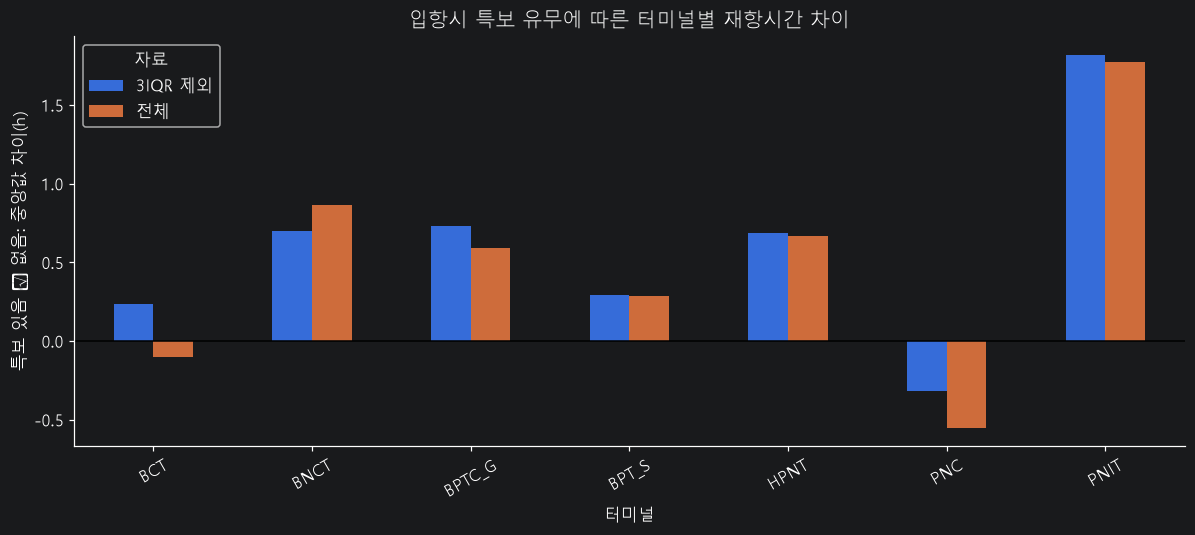

In [21]:
# 이 셀은 다른 노트북에서 가져온 분석이라 df_all / df_clean 이름을 씁니다.
# 이 노트북의 2020~2024년 유효 기항(ships)으로 같은 형태의 표를 만듭니다.
df_all = ships.rename(columns={
    "row_id": "원본엑셀행", "ship_name": "선박명",
    "terminal": "터미널", "arrival": "입항일시", "stay_h": "재항시간_h",
})[["원본엑셀행", "선박명", "터미널", "입항일시", "재항시간_h"]].copy()
df_all["원본엑셀행"] = pd.to_numeric(df_all["원본엑셀행"], errors="coerce").astype("Int64")
# 배 이름 끝의 탭·공백, 중복 공백 때문에 같은 배가 다르게 비교되지 않도록 정리
df_all["선박명"] = df_all["선박명"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df_all["터미널"] = df_all["터미널"].astype(str).str.strip()

# 3IQR 제외: 전체 재항시간 기준 Q1-3×IQR ~ Q3+3×IQR 밖의 기록을 제외
q1, q3 = df_all["재항시간_h"].quantile([0.25, 0.75])
iqr = q3 - q1
df_clean = df_all.loc[df_all["재항시간_h"].between(q1 - 3 * iqr, q3 + 3 * iqr)].copy()
print(f"전체 {len(df_all):,}건 / 3IQR 제외 후 {len(df_clean):,}건 (상한 {q3 + 3 * iqr:.1f}시간)")

# 실제 파일에 있는 입항시 특보 발효 여부를 불러옵니다.
aux = pd.read_excel(
    FILE_PATH,
    sheet_name="비교분석_핵심열",
    usecols=[
        "원본행번호_엑셀", "선박명", "터미널", "입항일시",
        "입항시_특보발효여부", "입항시_특보ID"
    ]
).rename(columns={
    "원본행번호_엑셀": "원본엑셀행"
})
aux["원본엑셀행"] = pd.to_numeric(aux["원본엑셀행"], errors="coerce").astype("Int64")
aux["선박명"] = aux["선박명"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
aux["터미널"] = aux["터미널"].astype(str).str.strip()

if aux["원본엑셀행"].duplicated().any():
    raise ValueError("특보 자료의 원본 행 번호가 중복됩니다.")

# 행 번호가 같은 기항을 가리키는지 검증합니다.
check = df_all[[
    "원본엑셀행", "선박명", "터미널", "입항일시"
]].merge(
    aux,
    on="원본엑셀행",
    how="left",
    validate="one_to_one",
    suffixes=("", "_검증"),
    indicator=True
)

matched = (
    check["_merge"].eq("both")
    & check["선박명"].eq(check["선박명_검증"])
    & check["터미널"].eq(check["터미널_검증"])
    & pd.to_datetime(check["입항일시"]).eq(
        pd.to_datetime(check["입항일시_검증"])
    )
)

if not matched.fillna(False).all():
    raise ValueError("두 시트의 기항 연결이 일치하지 않습니다.")

lookup = aux.set_index("원본엑셀행")

# 두 자료에서 동일한 장기 체류 기준을 사용합니다.
# 연구상 기준: 전체 자료 재항시간의 상위 10% 경계
long_stay_cutoff = df_all["재항시간_h"].quantile(0.90)
print(f"장기 체류 기준: {long_stay_cutoff:.2f}시간 이상")

summaries = []
differences = []

for sample_name, frame in [
    ("전체", df_all),
    ("3IQR 제외", df_clean)
]:
    data = frame.copy()

    data["특보"] = pd.to_numeric(
        data["원본엑셀행"].map(
            lookup["입항시_특보발효여부"]
        ),
        errors="coerce"
    )
    data["특보ID"] = data["원본엑셀행"].map(
        lookup["입항시_특보ID"]
    )

    # 미확인 상태를 특보 없음(0)으로 채우지 않습니다.
    unknown = ~data["특보"].isin([0, 1])
    print(f"{sample_name}: 특보 상태 미확인 {unknown.sum():,}건")
    data = data.loc[~unknown].copy()

    data["장기체류"] = (
        data["재항시간_h"] >= long_stay_cutoff
    )

    summary = (
        data.groupby(["터미널", "특보"])
        .agg(
            기항수=("재항시간_h", "count"),
            평균_h=("재항시간_h", "mean"),
            중앙값_h=("재항시간_h", "median"),
            장기체류비율=("장기체류", "mean")
        )
        .reset_index()
    )
    summary.insert(0, "자료", sample_name)
    summaries.append(summary)

    for terminal, group in data.groupby("터미널"):
        normal = group.loc[group["특보"].eq(0)]
        warning = group.loc[group["특보"].eq(1)]

        if normal.empty or warning.empty:
            continue

        differences.append({
            "자료": sample_name,
            "터미널": terminal,
            "특보없음_n": len(normal),
            "특보있음_n": len(warning),
            "특보ID수": warning["특보ID"].nunique(),
            "평균차_h":
                warning["재항시간_h"].mean()
                - normal["재항시간_h"].mean(),
            "중앙값차_h":
                warning["재항시간_h"].median()
                - normal["재항시간_h"].median(),
            "장기체류비율차_%p": 100 * (
                warning["장기체류"].mean()
                - normal["장기체류"].mean()
            )
        })

warning_summary = pd.concat(summaries, ignore_index=True)
warning_difference = pd.DataFrame(differences)

print("특보 0=입항 당시 미발효, 1=발효")
display(warning_summary.round(3))
display(warning_difference.round(3))

if warning_difference.empty:
    raise ValueError("특보 있음/없음을 비교할 수 있는 터미널이 없습니다.")

ax = warning_difference.pivot(
    index="터미널",
    columns="자료",
    values="중앙값차_h"
).plot.bar(figsize=(11, 5))

ax.axhline(0, color="black", linewidth=1)
ax.set(
    title="입항시 특보 유무에 따른 터미널별 재항시간 차이",
    ylabel="특보 있음 − 없음: 중앙값 차이(h)",
    xlabel="터미널"
)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()